# NLP analysis of the Piecemaker annotations: Theatrical Arsenal II

Text analysis of the annotations to *Theatrical Arsenal II* (2009) from the Piecemaker archive of The Forsythe Company. The corpus covers the rehearsal process up to the second performance on 26 November 2009. The pipeline mirrors the Sider notebook; the figure labels are in German here.

In [1]:
import re
from collections import Counter
from datetime import datetime
from pathlib import Path

import nltk
import spacy
import contractions
import pandas as pd
import numpy as np
from tqdm import tqdm
from sklearn.feature_extraction.text import CountVectorizer
from scipy.stats import spearmanr
from nltk.corpus import stopwords, brown
from nltk.tokenize import sent_tokenize
from nltk.collocations import BigramCollocationFinder
from nltk.metrics import BigramAssocMeasures
from bertopic import BERTopic
from plotnine import *

In [2]:
# Download required NLTK data (only needs to run once)
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('brown')

[nltk_data] Downloading package punkt to /Users/david/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /Users/david/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /Users/david/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package brown to /Users/david/nltk_data...
[nltk_data]   Package brown is already up-to-date!


True

In [3]:
nlp = spacy.load("en_core_web_sm")
nlp.max_length = 5_000_000

## Setup

The two csv files with the archive export are read from the repository folder; they are not included here because the annotation data are not public. `LANG` sets the figure labels to English or German.


In [4]:
PIECE_ID = 52          # Theatrical Arsenal II
PIECE_TITLE = 'Theatrical Arsenal II'
filter_date = datetime(2009, 11, 26).date()    # up to the second performance

print(f'PIECE_ID={PIECE_ID}, analysing annotations before {filter_date}')

PIECE_ID=52, analysing annotations before 2009-11-26


In [5]:
LANG = 'de'   # 'de' or 'en', switches the figure labels

def L(de, en, lang=None):
    return de if (lang or LANG) == 'de' else en

PASTEL_CYCLE = ['#cd867e', '#7ec5cd', '#7ecd86', '#867ecd', '#c5cd7e', '#cd7ec5']
BAR_GREY   = '#6b6b6b'
ACCENT_RED = '#d6604d'
# line types and shapes for black-and-white print
LINETYPES = ['solid', 'dashed', 'dotted', 'dashdot']
SHAPES    = ['o', 's', '^', 'D']

theme_set(
    theme_minimal()
    + theme(plot_title=element_text(size=12),
            plot_subtitle=element_text(size=9),
            legend_title=element_blank())
)

# print size for the dissertation figures
PRINT_SIZE  = (5.8, 2.9)
PRINT_THEME = theme(text=element_text(size=8), plot_title=element_text(size=9),
                    plot_subtitle=element_text(size=7.5), axis_title=element_text(size=8),
                    axis_text=element_text(size=7.5), legend_text=element_text(size=7.5),
                    legend_title=element_blank())
FIG_DIR = Path('figures')

def de_num(x, digits=2):
    # decimal comma for German labels
    return f'{x:.{digits}f}'.replace('.', ',')

In [6]:
pieces_df = pd.read_csv("pm1-tfc-2016-pieces.csv")
events_df = pd.read_csv("pm1-tfc-2016-events.csv")
piece_map = pieces_df.set_index("id")["title"].to_dict()

In [7]:
text_df = events_df[events_df['piece_id'] == PIECE_ID].copy()

# drop entries that are only a file name (video entries)
filename_pattern = re.compile(r'^(\d{6,}|\d{4}-\d{2}-\d{2}).*\.\w{2,4}$', re.IGNORECASE)
is_filename_title = text_df['title'].apply(
    lambda t: bool(filename_pattern.match(str(t))) if pd.notna(t) else False
)
is_filename_desc = text_df['description'].apply(
    lambda d: bool(filename_pattern.match(str(d))) if pd.notna(d) else False
)
text_df = text_df[~(is_filename_title & (text_df['description'].isna() | is_filename_desc))].copy()

def combine_annotation_text(row):
    title = str(row["title"]) if pd.notna(row["title"]) else ""
    description = str(row["description"]) if pd.notna(row["description"]) else ""
    if filename_pattern.match(title.strip()):
        title = ""
    if title and not title.endswith("."):
        title += "."
    return f"{title} {description}".strip()

text_df["text"] = text_df.apply(combine_annotation_text, axis=1)
text_df["date"] = pd.to_datetime(text_df["happened_at"])
text_df["date_only"] = text_df["date"].dt.date

text_df = text_df[text_df["date_only"] < filter_date].copy()

print(f"\nAnalyzing: {piece_map.get(PIECE_ID, 'Unknown')}")
print(f"Total annotations: {len(text_df)}")
print(f"Date range: {text_df['date'].min()} to {text_df['date'].max()}")


Analyzing: Theatrical Arsenal 2*
Total annotations: 637
Date range: 2009-10-22 08:18:36 to 2009-11-21 23:14:03


## Preprocessing

Title and description are combined into one text per annotation, cleaned (markup, numbers, contractions) and lemmatised with spaCy. NLTK stopwords plus a hand-compiled list of company member names are excluded from all counts.


In [8]:
def clean_text(text):
    if pd.isna(text) or not text:
        return ""
    text = contractions.fix(text)
    text = re.sub(r"[\n\r\*]+", " ", text)
    text = re.sub(r"__+", " ", text)
    text = re.sub(r"\b\d+\b", "", text)
    text = re.sub(r"(?<=\w)-(?=\w)", " ", text)
    text = re.sub(r"<br\s*/?>", " ", text, flags=re.IGNORECASE)
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"[<>]", " ", text)
    text = re.sub(r"\s{2,}", " ", text).strip()
    return text

text_df["clean_text"] = text_df["text"].apply(clean_text)
text_df = text_df[text_df["clean_text"].str.len() > 0].copy()
print(f"Events after cleaning: {len(text_df)}")

Events after cleaning: 624


In [9]:
# who wrote the annotations (initials as in pm1_archive_analytics; part of the export has no author)
def first_name(s):
    return s.str.lower().str.extract(r'^([a-z]+)')[0].str.capitalize()

all_names = first_name(pd.read_csv('pm1-tfc-2016-events.csv', usecols=['created_by'])['created_by'])
initials, used = {}, set()
for name in all_names.value_counts().index:
    label, k = name[0] + '.', 2
    while label in used:
        label, k = name[:k] + '.', k + 1
    used.add(label)
    initials[name] = label

authors = first_name(text_df['created_by']).map(initials).fillna('(no author in export)')
author_shares = (authors.value_counts(normalize=True) * 100).round(1)
print(author_shares.to_string())

0
(no author in export)    37.7
Ma.                      31.6
F.                       21.3
B.                        3.4
L.                        3.2
Pr.                       1.0
D.                        1.0
Sy.                       0.3
V.                        0.3
E.                        0.2
Bi.                       0.2


In [10]:
def lemmatize_with_spacy(text):
    doc = nlp(text)
    return " ".join(
        token.lemma_.lower()
        for token in doc
        if token.is_alpha and not token.is_stop and len(token.lemma_) >= 2
    )

text_df["lem_text"] = [
    lemmatize_with_spacy(txt)
    for txt in tqdm(text_df["clean_text"], desc="Lemmatizing")
]

Lemmatizing:   0%|          | 0/624 [00:00<?, ?it/s]

Lemmatizing:   0%|          | 1/624 [00:00<01:42,  6.11it/s]

Lemmatizing:   1%|          | 7/624 [00:00<00:21, 28.16it/s]

Lemmatizing:   3%|▎         | 16/624 [00:00<00:12, 49.46it/s]

Lemmatizing:   5%|▍         | 31/624 [00:00<00:07, 79.67it/s]

...

Lemmatizing:  93%|█████████▎| 579/624 [00:07<00:00, 65.69it/s]

Lemmatizing:  95%|█████████▌| 593/624 [00:07<00:00, 82.52it/s]

Lemmatizing:  97%|█████████▋| 603/624 [00:07<00:00, 80.69it/s]

Lemmatizing:  98%|█████████▊| 612/624 [00:07<00:00, 81.33it/s]

Lemmatizing: 100%|██████████| 624/624 [00:07<00:00, 79.59it/s]

In [11]:
# Manual stopword list - performer names and common terms to exclude
confirmed_names = [
    'amancio', 'ander', 'bill', 'billy', 'brigel', 'cy', 'cyril', 'dana',
    'dana/manci', 'dave', "dave's", 'david', "david's", 'esth', 'esther',
    'fab', 'fabrice', 'feya', 'freya', 'i."', 'jasu', 'john', 'jon', 'jone',
    'jones', 'josh', 'k.', 'kati', 'katy', 'katya', 'light=', 'liz', 'm2',
    'manci', 'mancie', 'mcdonald"', 'me!', 'monica', 'music=', 'nic',
    'nicole', 'pari', 'riley', 'rob', 'roberta', 'simon', 'steven',
    'stevens', 'tanja', 'til', 'tilman', 'w.', 'w.’s', 'w=', 'ya', 'yas',
    'yasu', 'yeah!"freya', 'yoko'
]
stop_en = set(stopwords.words("english"))
custom_stopwords = list(stop_en.union(confirmed_names))
print(f"Total stopwords: {len(custom_stopwords)}")

Total stopwords: 257


In [12]:
vectorizer = CountVectorizer(stop_words=custom_stopwords)
X = vectorizer.fit_transform(text_df["lem_text"])
words = vectorizer.get_feature_names_out()
counts = X.sum(axis=0).A1
word_freq = dict(zip(words, counts))

## Word frequency

The most frequent lemmas of the corpus. Not very telling on its own, but the baseline for everything below.


In [13]:
top_words_clean = Counter(word_freq).most_common(20)
print("\nTop 20 most frequent words:")
for word, count in top_words_clean:
    print(f"  {word}: {count}")


Top 20 most frequent words:
  music: 321
  light: 232
  come: 173
  sound: 171
  go: 170
  video: 165
  version: 154
  scene: 139
  try: 124
  enter: 123
  start: 119
  duet: 117
  like: 114
  say: 108
  material: 103
  leave: 97
  mic: 96
  quintett: 96
  wig: 96
  song: 92


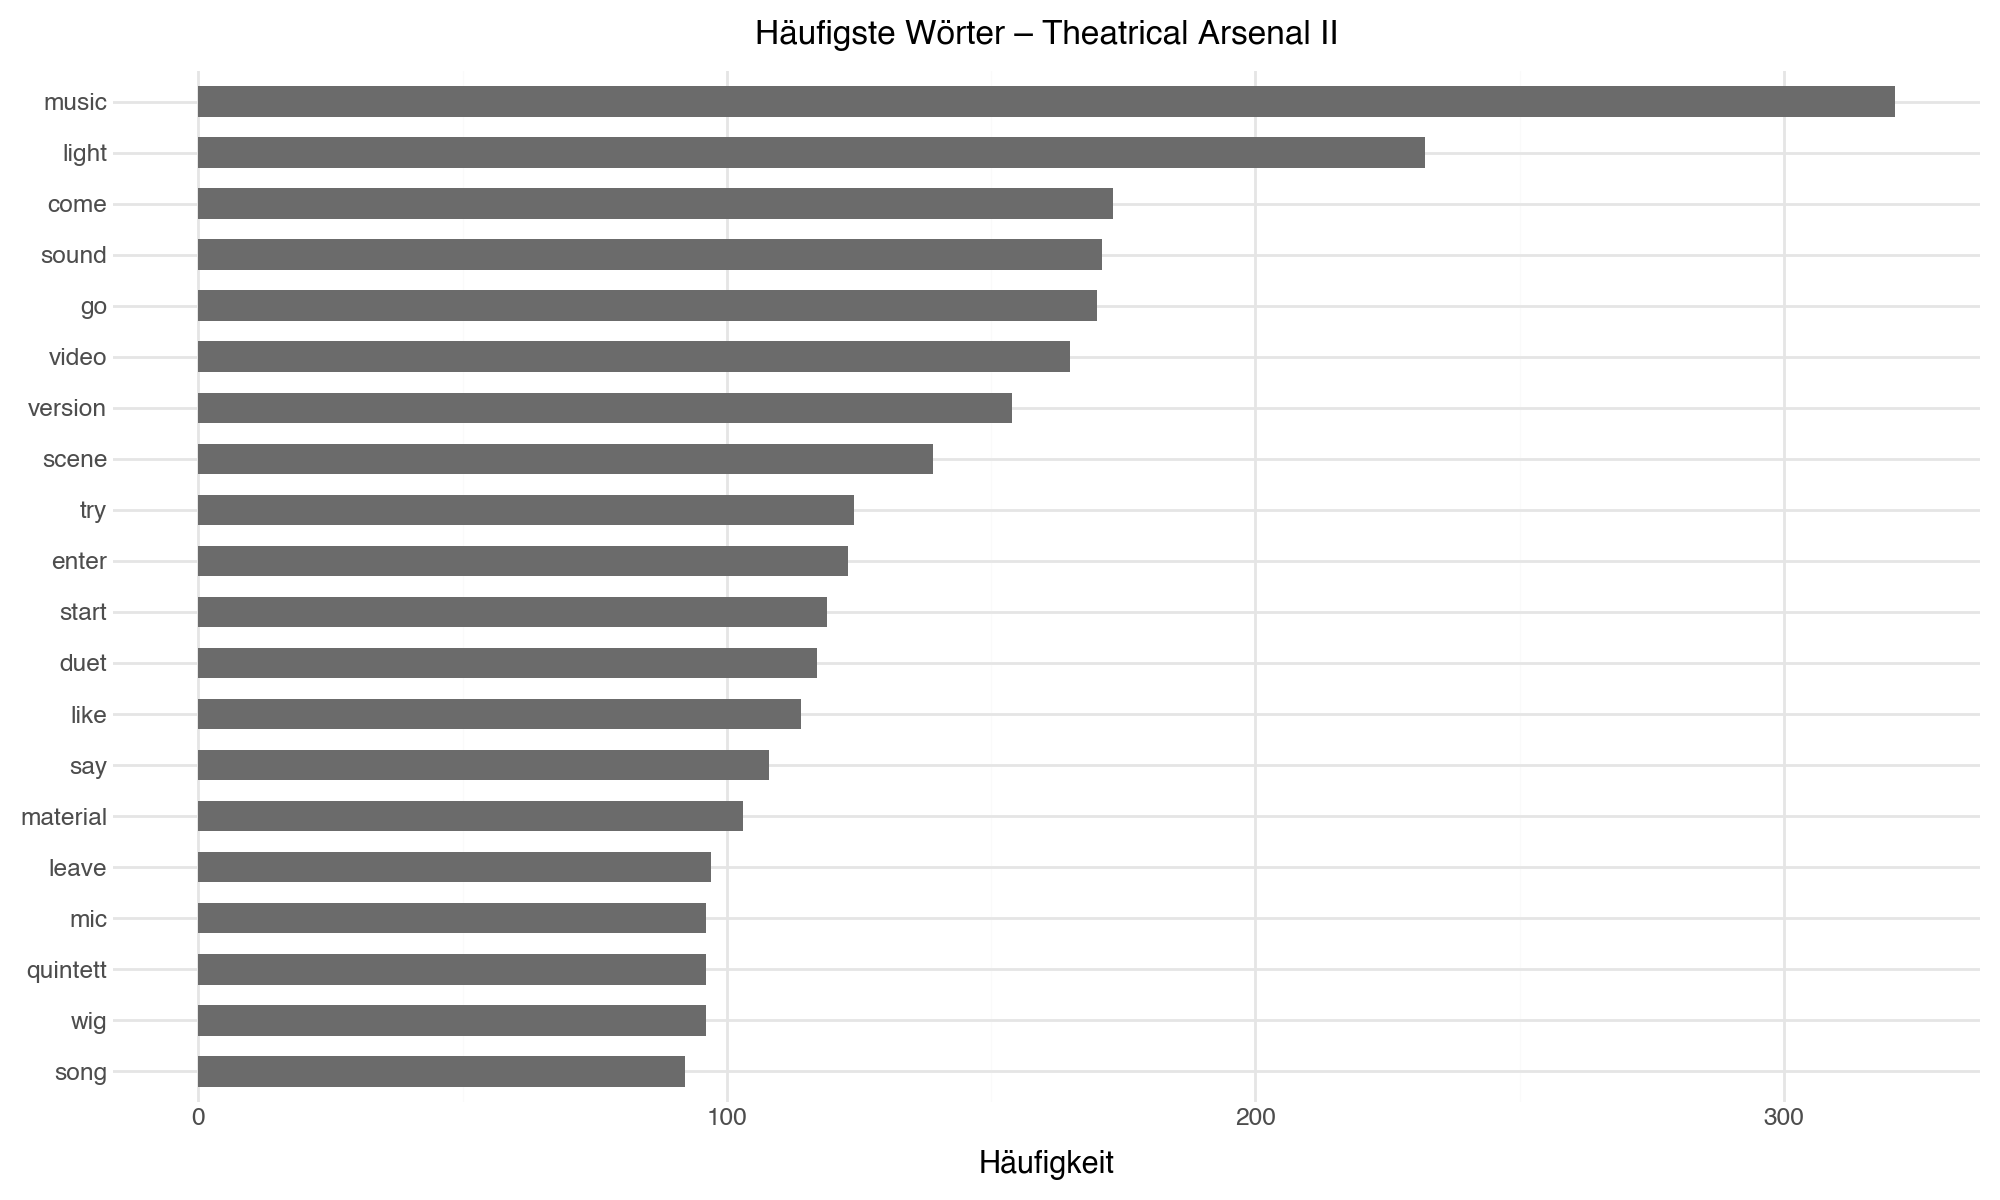

In [14]:
top_words_df = pd.DataFrame(top_words_clean, columns=['word', 'count'])
top_words_df['word'] = pd.Categorical(top_words_df['word'], categories=top_words_df['word'][::-1], ordered=True)

(ggplot(top_words_df, aes(x='word', y='count'))
 + geom_col(fill=BAR_GREY, width=0.6)
 + coord_flip()
 + labs(title=L('Häufigste Wörter – Theatrical Arsenal II', 'Top 20 Words – Theatrical Arsenal II'),
        x='', y=L('Häufigkeit', 'Frequency'))
 + theme(figure_size=(10, 6))
)

### Bigrams

Two-word sequences catch compound expressions that single-word counts miss.


In [15]:
bigram_freq = Counter()
for text in text_df["lem_text"]:
    tokens = text.split()
    filtered_tokens = [t for t in tokens if t.lower() not in custom_stopwords and len(t) > 2]
    bigrams = zip(filtered_tokens[:-1], filtered_tokens[1:])
    bigrams_str = [f"{w1} {w2}" for w1, w2 in bigrams]
    bigram_freq.update(bigrams_str)

top_bigrams = bigram_freq.most_common(20)
print("\nTop 20 bigrams:")
for bigram, count in top_bigrams:
    print(f"  {bigram}: {count}")


Top 20 bigrams:
  light video: 87
  video music: 79
  miss cleo: 45
  easy song: 44
  new version: 40
  music silence: 35
  basic beat: 31
  sound effect: 27
  talk death: 27
  music easy: 23
  leg arm: 22
  sound music: 22
  follow spot: 21
  soft piano: 20
  freestyle character: 19
  sound light: 19
  video sound: 19
  quintett quintet: 17
  music basic: 17
  kammer kammer: 17


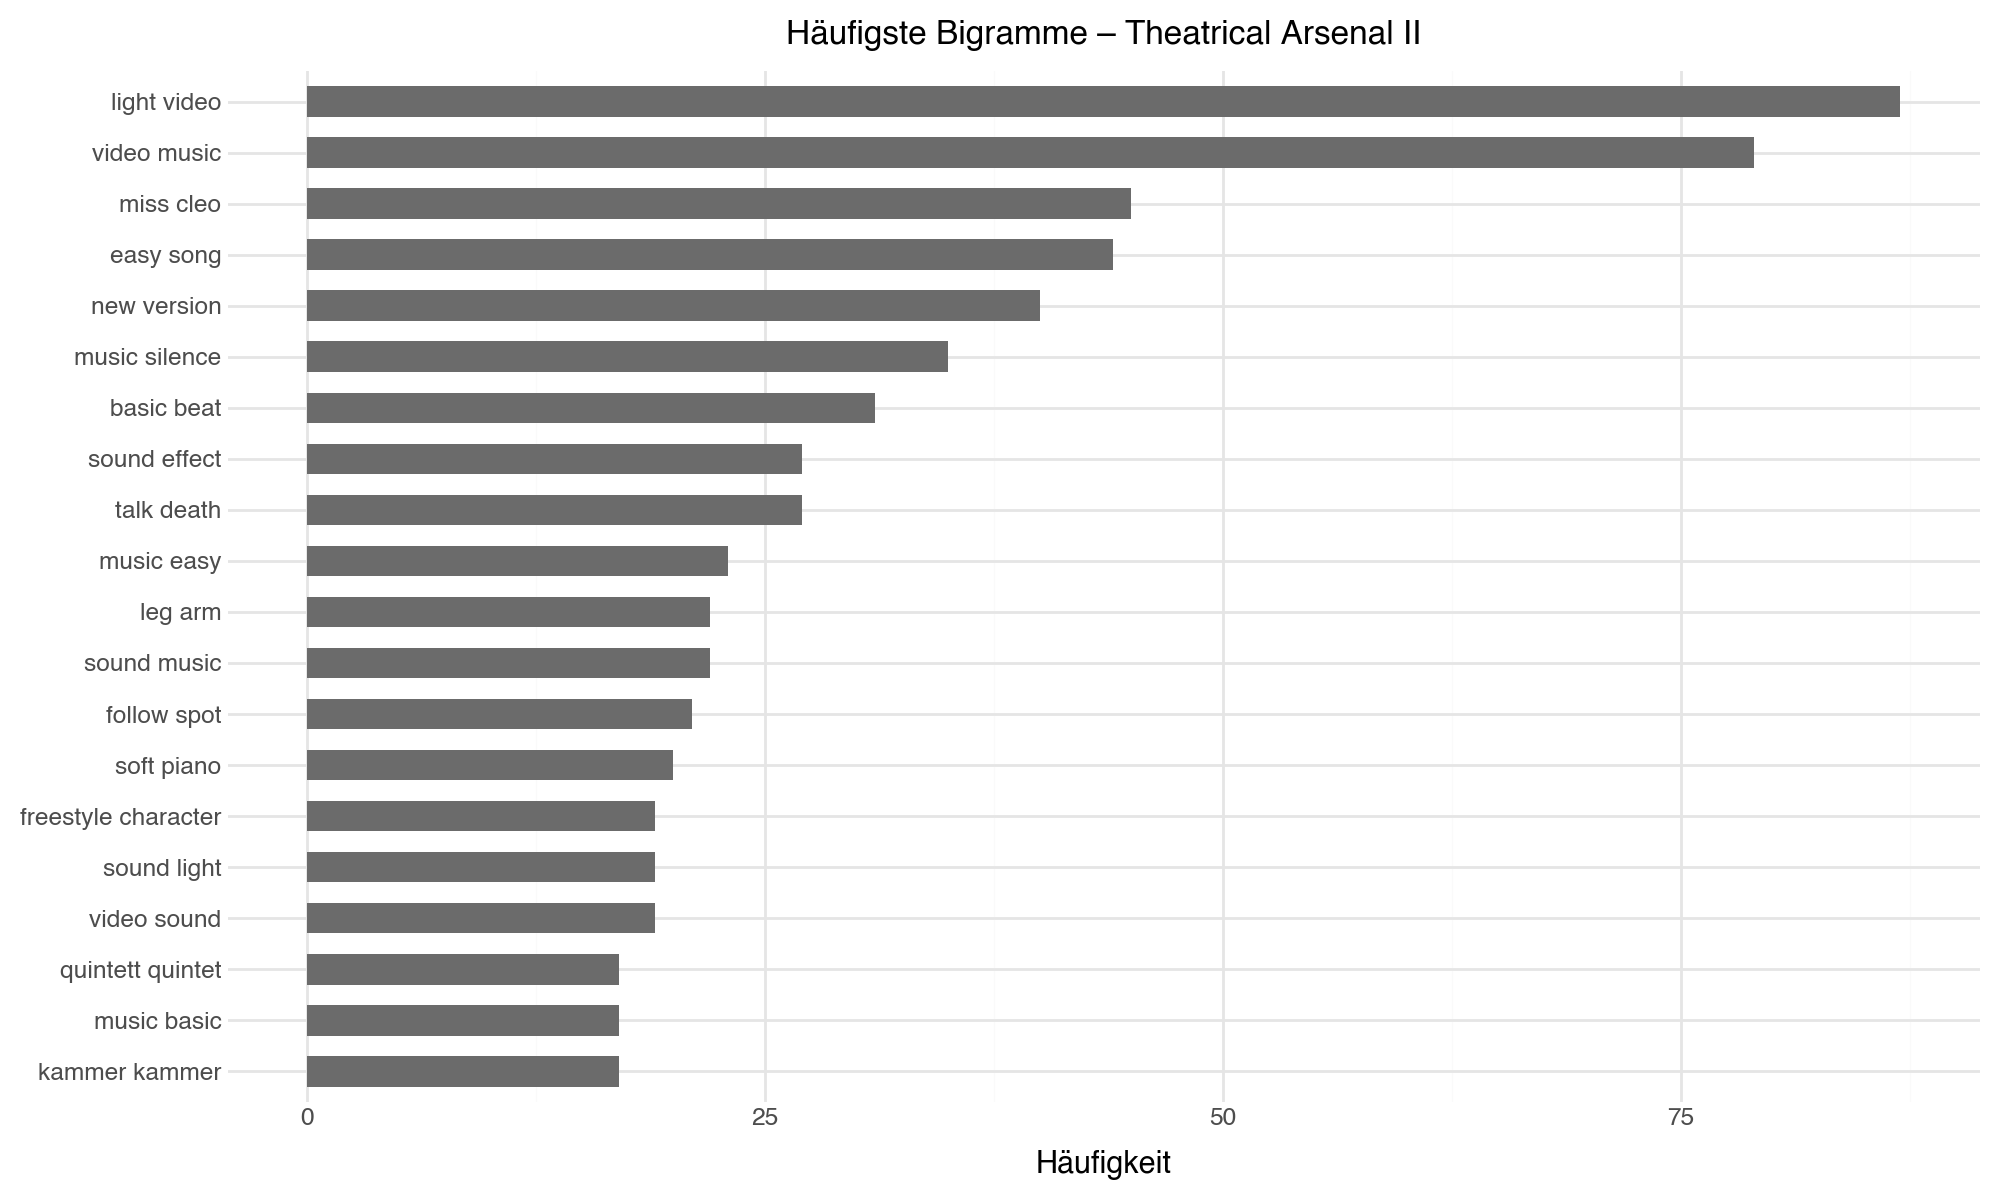

In [16]:
bigrams_df = pd.DataFrame(top_bigrams, columns=['bigram', 'count'])
bigrams_df['bigram'] = pd.Categorical(bigrams_df['bigram'], categories=bigrams_df['bigram'][::-1], ordered=True)

(ggplot(bigrams_df, aes(x='bigram', y='count'))
 + geom_col(fill=BAR_GREY, width=0.6)
 + coord_flip()
 + labs(title=L('Häufigste Bigramme – Theatrical Arsenal II', 'Top 20 Bigrams – Theatrical Arsenal II'),
        x='', y=L('Häufigkeit', 'Frequency'))
 + theme(figure_size=(10, 6))
)

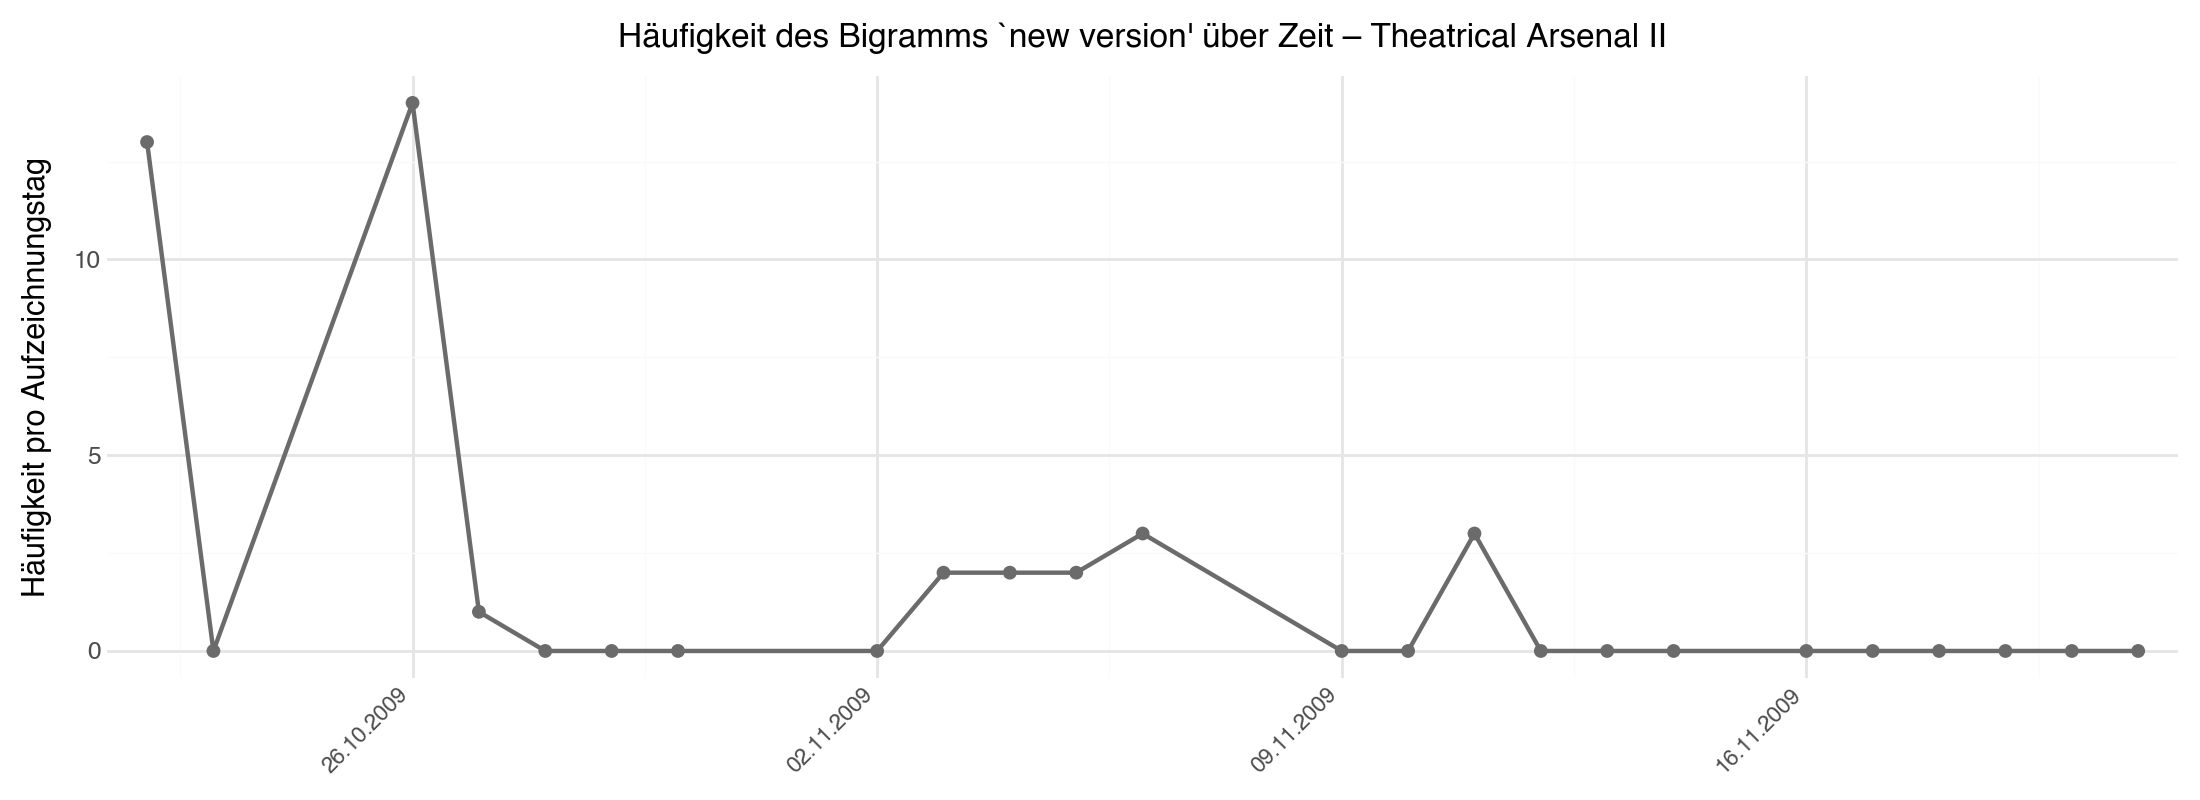

In [17]:
# `new version' per recording day
BIGRAM_TRACK = ('new', 'version')
GAP_DAYS = 3

rows_bg = []
for date, grp in text_df.groupby('date_only'):
    cnt = 0
    for text in grp['lem_text']:
        toks = [t for t in text.split() if t.lower() not in custom_stopwords and len(t) > 2]
        cnt += sum(1 for a, b in zip(toks[:-1], toks[1:]) if (a, b) == BIGRAM_TRACK)
    rows_bg.append({'date': pd.Timestamp(date), 'count': cnt})
bg_df = pd.DataFrame(rows_bg).sort_values('date')
gap_bg = bg_df['date'].diff().dt.days > GAP_DAYS
bg_df['line_group'] = gap_bg.cumsum()

p_bigram = (ggplot(bg_df, aes(x='date', y='count'))
 + geom_line(aes(group='line_group'), color=BAR_GREY, size=0.9)
 + geom_point(color=BAR_GREY, size=1.8)
 + scale_x_datetime(date_breaks='1 week', date_labels='%d.%m.%Y', expand=(0.02, 0))
 + labs(title=L("Häufigkeit des Bigramms `new version' über Zeit – Theatrical Arsenal II",
                "Bigram `new version' over time – Theatrical Arsenal II"),
        x='', y=L('Häufigkeit pro Aufzeichnungstag', 'Count per recording day'))
 + theme(figure_size=(11, 4),
         axis_text_x=element_text(rotation=45, hjust=1, size=8))
)
p_bigram

## Selected terms over time

Daily counts for a few terms that are central to this production, plotted on a calendar axis. Which terms to track is a manual choice based on knowing the piece.


In [18]:
track_terms = ['quintett', 'ywc', 'atmo', 'hypo']
term_colors = dict(zip(track_terms, PASTEL_CYCLE))
print(f"Tracking terms: {track_terms}")

word_counts_by_day = []
for date, group in text_df.groupby("date_only"):
    vectorizer_day = CountVectorizer(stop_words=custom_stopwords, vocabulary=track_terms)
    X_day = vectorizer_day.fit_transform(group["lem_text"])
    counts = X_day.sum(axis=0).A1
    for i, term in enumerate(track_terms):
        word_counts_by_day.append({
            'date': date,
            'word': term,
            'count': counts[i]
        })

word_day_df = pd.DataFrame(word_counts_by_day)
word_day_df['date'] = pd.to_datetime(word_day_df['date'])
word_day_df['word'] = pd.Categorical(word_day_df['word'], categories=track_terms, ordered=True)

Tracking terms: ['quintett', 'ywc', 'atmo', 'hypo']


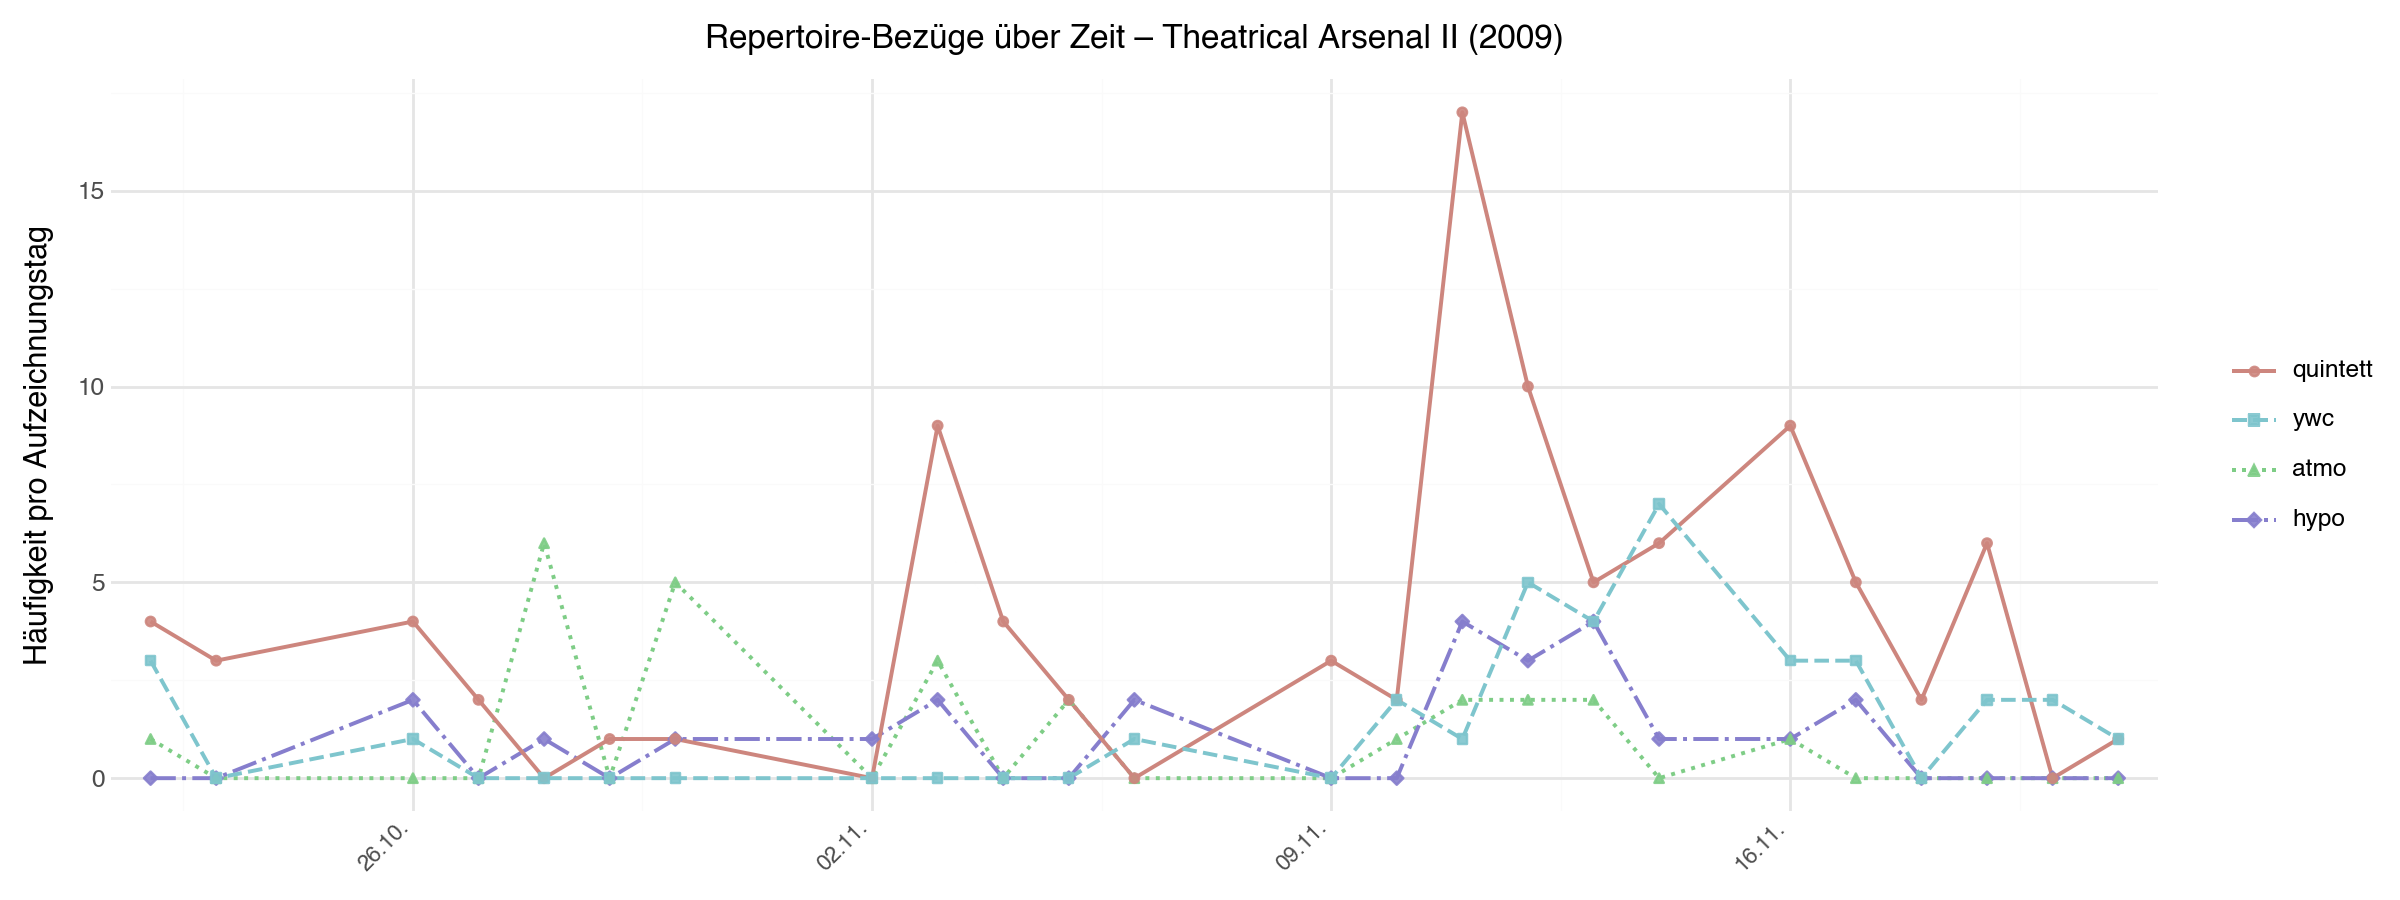

In [19]:
# lines break at gaps of more than GAP_DAYS days without recordings
GAP_DAYS = 3
word_day_df = word_day_df.sort_values(['word', 'date'])
gap = word_day_df.groupby('word', observed=True)['date'].diff().dt.days > GAP_DAYS
word_day_df['segment'] = gap.groupby(word_day_df['word'], observed=True).cumsum()
word_day_df['line_group'] = word_day_df['word'].astype(str) + '_' + word_day_df['segment'].astype(str)

def make_track_plot(lang=None):
    return (ggplot(word_day_df, aes(x='date', y='count', color='word', linetype='word', shape='word'))
     + geom_line(aes(group='line_group'), size=0.8)
     + geom_point(size=1.4, alpha=0.9)
     + scale_color_manual(values=term_colors, name='')
     + scale_linetype_manual(values=dict(zip(track_terms, LINETYPES)), name='')
     + scale_shape_manual(values=dict(zip(track_terms, SHAPES)), name='')
     + scale_x_datetime(date_breaks='1 week', date_labels='%d.%m.', expand=(0.02, 0))
     + labs(title=L('Repertoire-Bezüge über Zeit – Theatrical Arsenal II (2009)', 'References to the repertoire over time – Theatrical Arsenal II (2009)', lang),
            x='', y=L('Häufigkeit pro Aufzeichnungstag', 'Count per recording day', lang))
     + theme(figure_size=(12, 4.5),
             axis_text_x=element_text(rotation=45, hjust=1, size=8),
             legend_position='right'))

p_track = make_track_plot()
p_track

## Correlation over time

Which of the frequent words rise and fall together over the rehearsal days? Spearman rank correlation of the daily counts: on most days a word does not occur at all, and Pearson would be dominated by a few days with a lot of writing. I picked the pairs after looking at the matrix, so the p-values are only descriptive. To check that a correlation is not just the amount of writing per day, the same on relative frequencies (count per lemma token of the day).

In [20]:
cluster_terms = ['material', 'original', 'new', 'opposite']
top_words_corr = [t[0] for t in top_words_clean]
vocab = list(dict.fromkeys(top_words_corr + cluster_terms))  # top 20 + cluster terms

word_counts_by_day_corr = []
for date, group in text_df.groupby("date_only"):
    vectorizer_corr = CountVectorizer(stop_words=custom_stopwords, vocabulary=vocab)
    X_corr = vectorizer_corr.fit_transform(group["lem_text"])
    counts = X_corr.sum(axis=0).A1
    row_data = {'date': date}
    for i, word in enumerate(vocab):
        row_data[word] = counts[i]
    word_counts_by_day_corr.append(row_data)

result = pd.DataFrame(word_counts_by_day_corr).sort_values('date')
daily = result.drop(columns=['date'])

print(f"Days: {len(result)}")
print("\nSpearman rank correlation (cluster terms):")
print(daily[cluster_terms].corr(method='spearman').round(3))
print("\nFor comparison, Pearson (sensitive to outlier days, do not cite):")
print(daily[cluster_terms].corr(method='pearson').round(3))

# relative frequencies: count per lemma token of the day
day_tokens = (text_df.groupby('date_only')['lem_text']
              .apply(lambda s: sum(len(t.split()) for t in s))
              .reindex(result['date']).to_numpy())
rel_daily = daily[cluster_terms].div(day_tokens, axis=0)
corr_report = []
for t in cluster_terms[1:]:
    r_abs, p_abs = spearmanr(daily[cluster_terms[0]], daily[t])
    r_rel, p_rel = spearmanr(rel_daily[cluster_terms[0]], rel_daily[t])
    corr_report.append({'pair': f'{cluster_terms[0]}-{t}', 'days': len(result),
                        'rho_abs': round(r_abs, 3), 'p_abs': p_abs,
                        'rho_rel': round(r_rel, 3), 'p_rel': p_rel})
corr_report = pd.DataFrame(corr_report)
print("\nSpearman with p, absolute and relative daily counts:")
print(corr_report.to_string(index=False, formatters={'p_abs': '{:.2g}'.format, 'p_rel': '{:.2g}'.format}))

Days: 24

Spearman rank correlation (cluster terms):
          material  original    new  opposite
material     1.000     0.509  0.538     0.357
original     0.509     1.000  0.622     0.337
new          0.538     0.622  1.000     0.420
opposite     0.357     0.337  0.420     1.000

For comparison, Pearson (sensitive to outlier days, do not cite):
          material  original    new  opposite
material     1.000     0.596  0.585     0.114
original     0.596     1.000  0.920     0.591
new          0.585     0.920  1.000     0.564
opposite     0.114     0.591  0.564     1.000

Spearman with p, absolute and relative daily counts:
             pair  days  rho_abs  p_abs  rho_rel p_rel
material-original    24    0.509  0.011    0.401 0.052
     material-new    24    0.538 0.0067    0.476 0.019
material-opposite    24    0.357  0.087    0.315  0.13


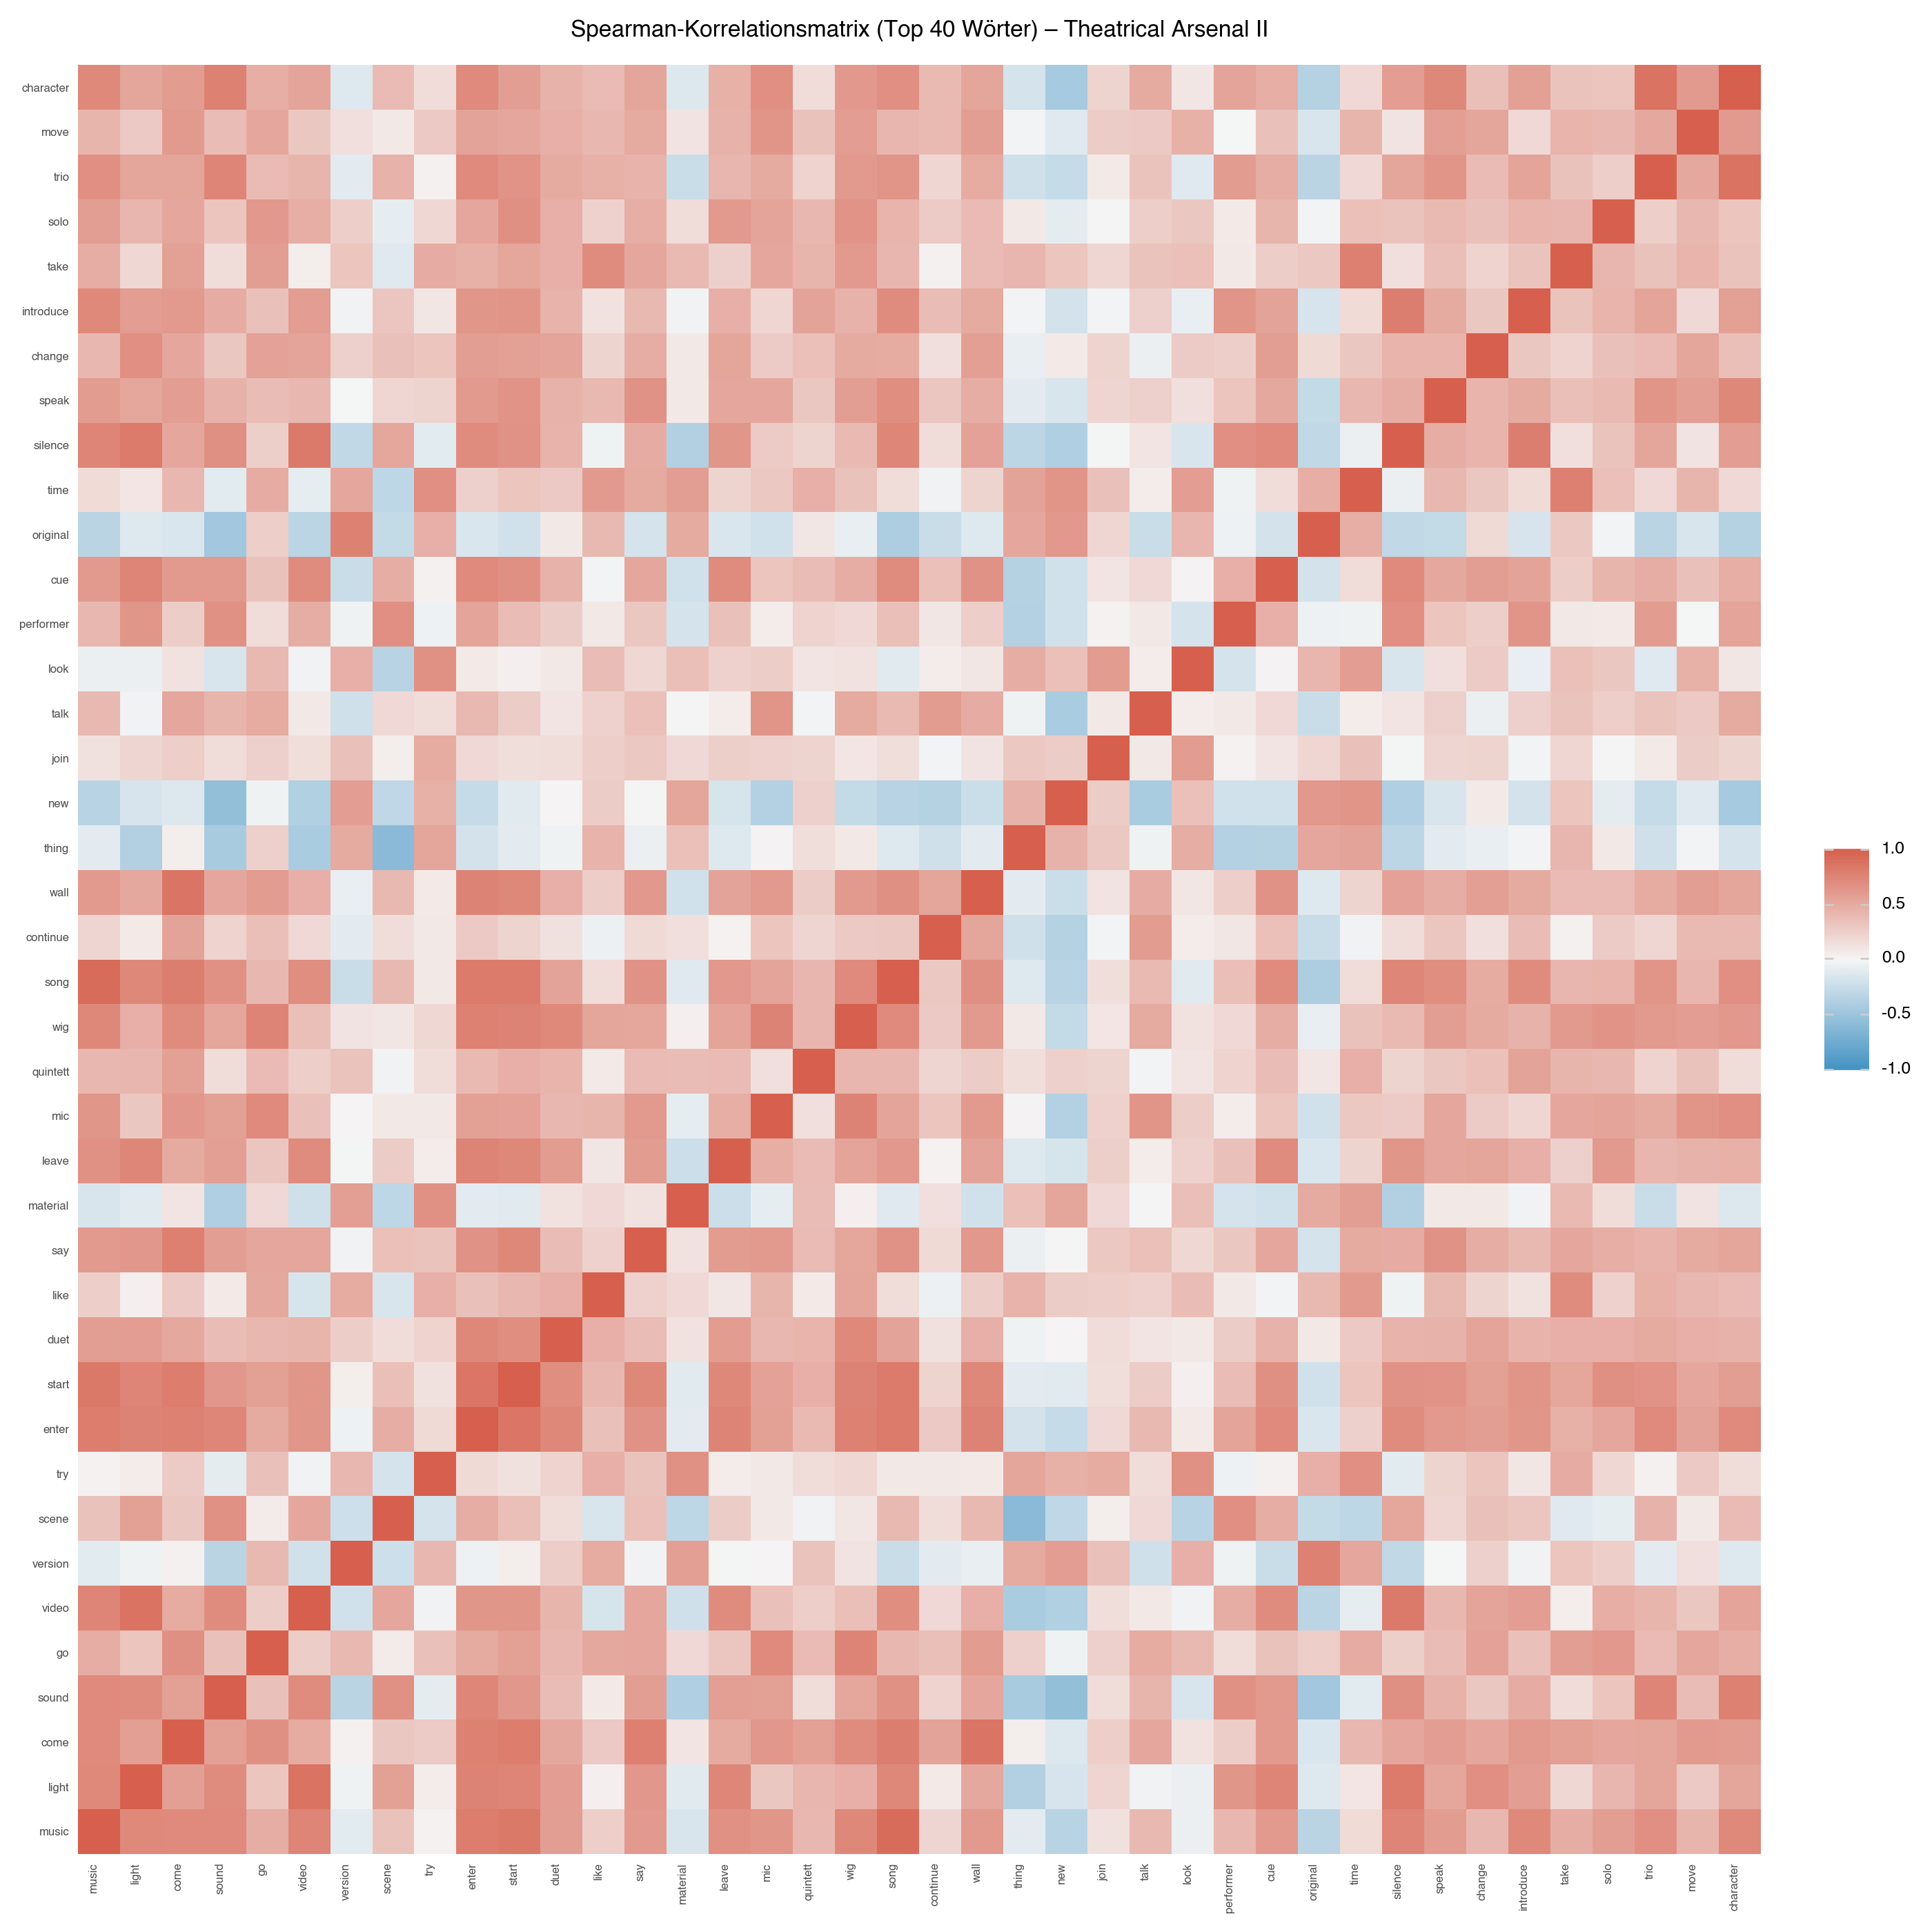

In [21]:
# heatmap of the top 40 words
corr_terms = [w for w, _ in Counter(word_freq).most_common(40)]

corr_counts_by_day = []
for date, group in text_df.groupby("date_only"):
    vectorizer_corr = CountVectorizer(stop_words=custom_stopwords, vocabulary=corr_terms)
    X_corr = vectorizer_corr.fit_transform(group["lem_text"])
    counts = X_corr.sum(axis=0).A1
    corr_counts_by_day.append({"date": date, **dict(zip(corr_terms, counts))})

corr_df = pd.DataFrame(corr_counts_by_day).set_index("date")
corr_matrix = corr_df.corr(method="spearman")

corr_long = (
    corr_matrix
    .reset_index()
    .melt(id_vars="index", var_name="word2", value_name="r")
    .rename(columns={"index": "word1"})
)
corr_long["word1"] = pd.Categorical(corr_long["word1"], categories=corr_terms, ordered=True)
corr_long["word2"] = pd.Categorical(corr_long["word2"], categories=corr_terms, ordered=True)

(ggplot(corr_long, aes(x="word1", y="word2", fill="r"))
 + geom_tile()
 + scale_fill_gradient2(low="#4393c3", mid="#f5f5f5", high="#d6604d", midpoint=0, limits=(-1, 1))
 + labs(title=L(f"Spearman-Korrelationsmatrix (Top {len(corr_terms)} Wörter) – Theatrical Arsenal II",
                f"Spearman Correlation Matrix (Top {len(corr_terms)} Words) – Theatrical Arsenal II"),
        x="", y="", fill="ρ")
 + theme(
     axis_text_x=element_text(rotation=90, hjust=1, size=6),
     axis_text_y=element_text(size=6),
     axis_ticks=element_blank(),
     panel_grid=element_blank(),
     figure_size=(14, 14)
 )
)

### Word pairs

Which words occur together more often than chance would suggest? Pairs within single annotations (stopwords removed, n ≥ 3), ranked by log-likelihood (G²). Ranked by PMI, the rarest pairs would come first; PMI and NPMI are listed for comparison.

In [22]:
print("\n=== Bigram association ===")

stop_en_pmi = set(stopwords.words("english"))
all_entities = set(confirmed_names)

def pmi_tokens(text):
    tokens = [w.lower() for w in nltk.word_tokenize(text) if w.isalpha()]
    return [w for w in tokens if w not in stop_en_pmi and w not in all_entities]

# one token list per annotation, so pairs don't cross annotations
doc_tokens = [pmi_tokens(t) for t in text_df["lem_text"]]

bigram_measures = BigramAssocMeasures()
finder = BigramCollocationFinder.from_documents(doc_tokens)
finder.apply_freq_filter(3)

N_bigrams = finder.N
pmi_scores = dict(finder.score_ngrams(bigram_measures.pmi))
g2_scores  = dict(finder.score_ngrams(bigram_measures.likelihood_ratio))
assoc = pd.DataFrame([
    {'bigram': f'{a} {b}', 'n': finder.ngram_fd[(a, b)], 'g2': g2_scores[(a, b)],
     'pmi': pmi_scores[(a, b)],
     'npmi': pmi_scores[(a, b)] / -np.log2(finder.ngram_fd[(a, b)] / N_bigrams)}
    for (a, b) in pmi_scores
]).sort_values('g2', ascending=False).reset_index(drop=True)

fmt = {'g2': '{:.1f}'.format, 'pmi': '{:.2f}'.format, 'npmi': '{:.2f}'.format}
print(f"Pairs with n >= 3: {len(assoc)} (bigram tokens: {N_bigrams})")
print("\nTop 20 word pairs by log-likelihood (G²):")
print(assoc.head(20).to_string(formatters=fmt))
print("\nFor comparison, top 20 by PMI:")
print(assoc.sort_values('pmi', ascending=False).head(20).to_string(formatters=fmt))


=== Bigram association ===
Pairs with n >= 3: 509 (bigram tokens: 14726)

Top 20 word pairs by log-likelihood (G²):
                 bigram   n    g2   pmi npmi
0             miss cleo  45 572.0  8.20 0.98
1           light video  85 514.0  5.03 0.68
2             easy song  44 449.8  7.23 0.86
3           video music  79 399.8  4.46 0.59
4            basic beat  31 363.0  8.20 0.92
5           new version  40 268.7  5.62 0.66
6          grand finale  17 240.4  9.39 0.96
7            talk death  27 236.7  6.89 0.76
8           follow spot  21 226.0  8.04 0.85
9            soft piano  20 211.3  7.95 0.83
10              leg arm  22 193.7  7.03 0.75
11         sound effect  27 186.7  5.72 0.63
12        music silence  35 180.2  4.58 0.53
13  freestyle character  19 174.1  7.24 0.75
14        kammer kammer  17 167.0  7.67 0.79
15             bad love  14 166.4  8.73 0.87
16              con gas  10 159.2 10.39 0.99
17       project screen  12 156.3  9.30 0.91
18     quintett quintet  17 

## Keyness against the Brown corpus

Which words are distinctive compared to general English? G² against the Brown corpus as a filter (p < 0.001), then ranked by Log Ratio, which brings up the rare but exclusive vocabulary. Brown is lemmatised with the same spaCy pipeline (cached in `brown_lemma_freq.csv`). Words missing from Brown get the substitute count 0.5, so their Log Ratio is only an ordering; they are marked in the figure. A bootstrap over the annotations shows how stable the top 30 are.

In [23]:
BROWN_CACHE = 'brown_lemma_freq.csv'

if Path(BROWN_CACHE).exists():
    brown_freq = pd.read_csv(BROWN_CACHE).set_index('lemma')['count'].to_dict()
    print(f'Loaded lemmatised Brown frequencies from cache ({len(brown_freq)} lemma types)')
else:
    print('Building lemmatised Brown frequency cache (one-off, ~2 min)...')
    _nlp_fast = spacy.load('en_core_web_sm', disable=['parser', 'ner'])
    _freq = Counter()
    _sents = [' '.join(s) for s in brown.sents()]
    for _doc in _nlp_fast.pipe(_sents, batch_size=200):
        _freq.update(
            tok.lemma_.lower() for tok in _doc
            if tok.is_alpha and not tok.is_stop and len(tok.lemma_) >= 2
        )
    pd.DataFrame(sorted(_freq.items()), columns=['lemma', 'count']).to_csv(BROWN_CACHE, index=False)
    brown_freq = dict(_freq)
    print(f'Saved {BROWN_CACHE} ({len(brown_freq)} lemma types)')

N_your = int(sum(word_freq.values()))
N_ref  = int(sum(brown_freq.values()))
print(f'Target corpus tokens: {N_your}')
print(f'Reference corpus tokens (Brown, lemmatised): {N_ref}')

Loaded lemmatised Brown frequencies from cache (32531 lemma types)
Target corpus tokens: 14726
Reference corpus tokens (Brown, lemmatised): 469996


In [24]:
MIN_FREQ = 5        # minimum frequency in the target corpus
G2_CRIT  = 10.83    # p < 0.001

def compute_g2(O1, O2, N1, N2):
    """Dunning's G² (signed: positive = overrepresented in the target corpus)."""
    def safe_log(x):
        return np.log(x) if x > 0 else 0.0
    N = N1 + N2
    p  = (O1 + O2) / N if N > 0 else 0.0
    p1 = O1 / N1 if N1 > 0 else 0.0
    p2 = O2 / N2 if N2 > 0 else 0.0
    L_null = (O1 * safe_log(p)  + (N1 - O1) * safe_log(1 - p) +
              O2 * safe_log(p)  + (N2 - O2) * safe_log(1 - p))
    L_alt  = (O1 * safe_log(p1) + (N1 - O1) * safe_log(1 - p1) +
              O2 * safe_log(p2) + (N2 - O2) * safe_log(1 - p2))
    g2 = 2 * (L_alt - L_null)
    return g2 if p1 >= p2 else -g2

def log_ratio(O1, O2, N1, N2):
    """Hardie's Log Ratio; zero counts are replaced by 0.5."""
    return float(np.log2(((O1 if O1 > 0 else 0.5) / N1) /
                         ((O2 if O2 > 0 else 0.5) / N2)))

rows = []
for word, O1 in word_freq.items():
    if O1 < MIN_FREQ:
        continue
    O2 = brown_freq.get(word, 0)
    rows.append({
        'word': word, 'your_count': int(O1), 'ref_count': int(O2),
        'g2': compute_g2(O1, O2, N_your, N_ref),
        'log_ratio': log_ratio(O1, O2, N_your, N_ref),
    })
keyness_ref = pd.DataFrame(rows)

keyness_sig = (
    keyness_ref[keyness_ref['g2'] >= G2_CRIT]
    .sort_values('log_ratio', ascending=False)
    .reset_index(drop=True)
)
print(f'Words with frequency >= {MIN_FREQ}: {len(keyness_ref)}')
print(f'Significant at p < 0.001 (G² >= {G2_CRIT}): {len(keyness_sig)}')
print('\nTop 30 by Log Ratio:')
print(keyness_sig.head(30).to_string(index=False,
      formatters={'g2': '{:.1f}'.format, 'log_ratio': '{:+.2f}'.format}))

B_BOOT = 200
rng = np.random.default_rng(42)
doc_vectorizer = CountVectorizer(stop_words=custom_stopwords)
X_docs = doc_vectorizer.fit_transform(text_df['lem_text'])
boot_vocab = doc_vectorizer.get_feature_names_out()
ref_counts = np.array([brown_freq.get(w, 0) for w in boot_vocab])
top30 = keyness_sig.head(30)['word'].tolist()
in_top30 = Counter()
for _ in range(B_BOOT):
    rows_b = rng.integers(0, X_docs.shape[0], X_docs.shape[0])
    counts_b = np.asarray(X_docs[rows_b].sum(axis=0)).ravel()
    N_b = counts_b.sum()
    cand = [(w, log_ratio(o1, o2, N_b, N_ref)) for w, o1, o2 in zip(boot_vocab, counts_b, ref_counts)
            if o1 >= MIN_FREQ and compute_g2(o1, o2, N_b, N_ref) >= G2_CRIT]
    ranked = {w for w, _ in sorted(cand, key=lambda r: -r[1])[:30]}
    in_top30.update(w for w in top30 if w in ranked)
keyness_sig['top30_share'] = keyness_sig['word'].map(lambda w: in_top30[w] / B_BOOT if w in top30 else np.nan)
keyness_sig['absent_in_ref'] = keyness_sig['ref_count'] == 0
print(f'\nBootstrap ({B_BOOT} resamples): share in which a word is in the top 30 again')
print(keyness_sig.head(30)[['word', 'your_count', 'ref_count', 'log_ratio', 'top30_share']].to_string(index=False,
      formatters={'log_ratio': '{:+.2f}'.format, 'top30_share': '{:.2f}'.format}))
print(f"Median stability of the top 30: {keyness_sig.head(30)['top30_share'].median():.2f}")

Words with frequency >= 5: 585
Significant at p < 0.001 (G² >= 10.83): 313

Top 30 by Log Ratio:
          word  your_count  ref_count     g2 log_ratio
      quintett          96          0  671.4    +12.58
           mic          96          0  671.4    +12.58
           wig          96          1  660.4    +11.58
          cleo          47          0  328.6    +11.55
      lipsynch          42          0  293.6    +11.39
         video         165          2 1133.3    +11.36
        kammer          35          0  244.7    +11.13
           ywc          35          0  244.7    +11.13
     freestyle          33          0  230.7    +11.04
     lipsynchs          30          0  209.7    +10.90
          duet         117          2  798.3    +10.87
        contra          27          0  188.7    +10.75
          atmo          25          0  174.7    +10.64
          hypo          24          0  167.7    +10.58
    antichrist          22          0  153.8    +10.46
           dvd         


Bootstrap (200 resamples): share in which a word is in the top 30 again
          word  your_count  ref_count log_ratio top30_share
      quintett          96          0    +12.58        1.00
           mic          96          0    +12.58        1.00
           wig          96          1    +11.58        1.00
          cleo          47          0    +11.55        1.00
      lipsynch          42          0    +11.39        1.00
         video         165          2    +11.36        1.00
        kammer          35          0    +11.13        1.00
           ywc          35          0    +11.13        1.00
     freestyle          33          0    +11.04        1.00
     lipsynchs          30          0    +10.90        1.00
          duet         117          2    +10.87        1.00
        contra          27          0    +10.75        1.00
          atmo          25          0    +10.64        1.00
          hypo          24          0    +10.58        1.00
    antichrist          22 

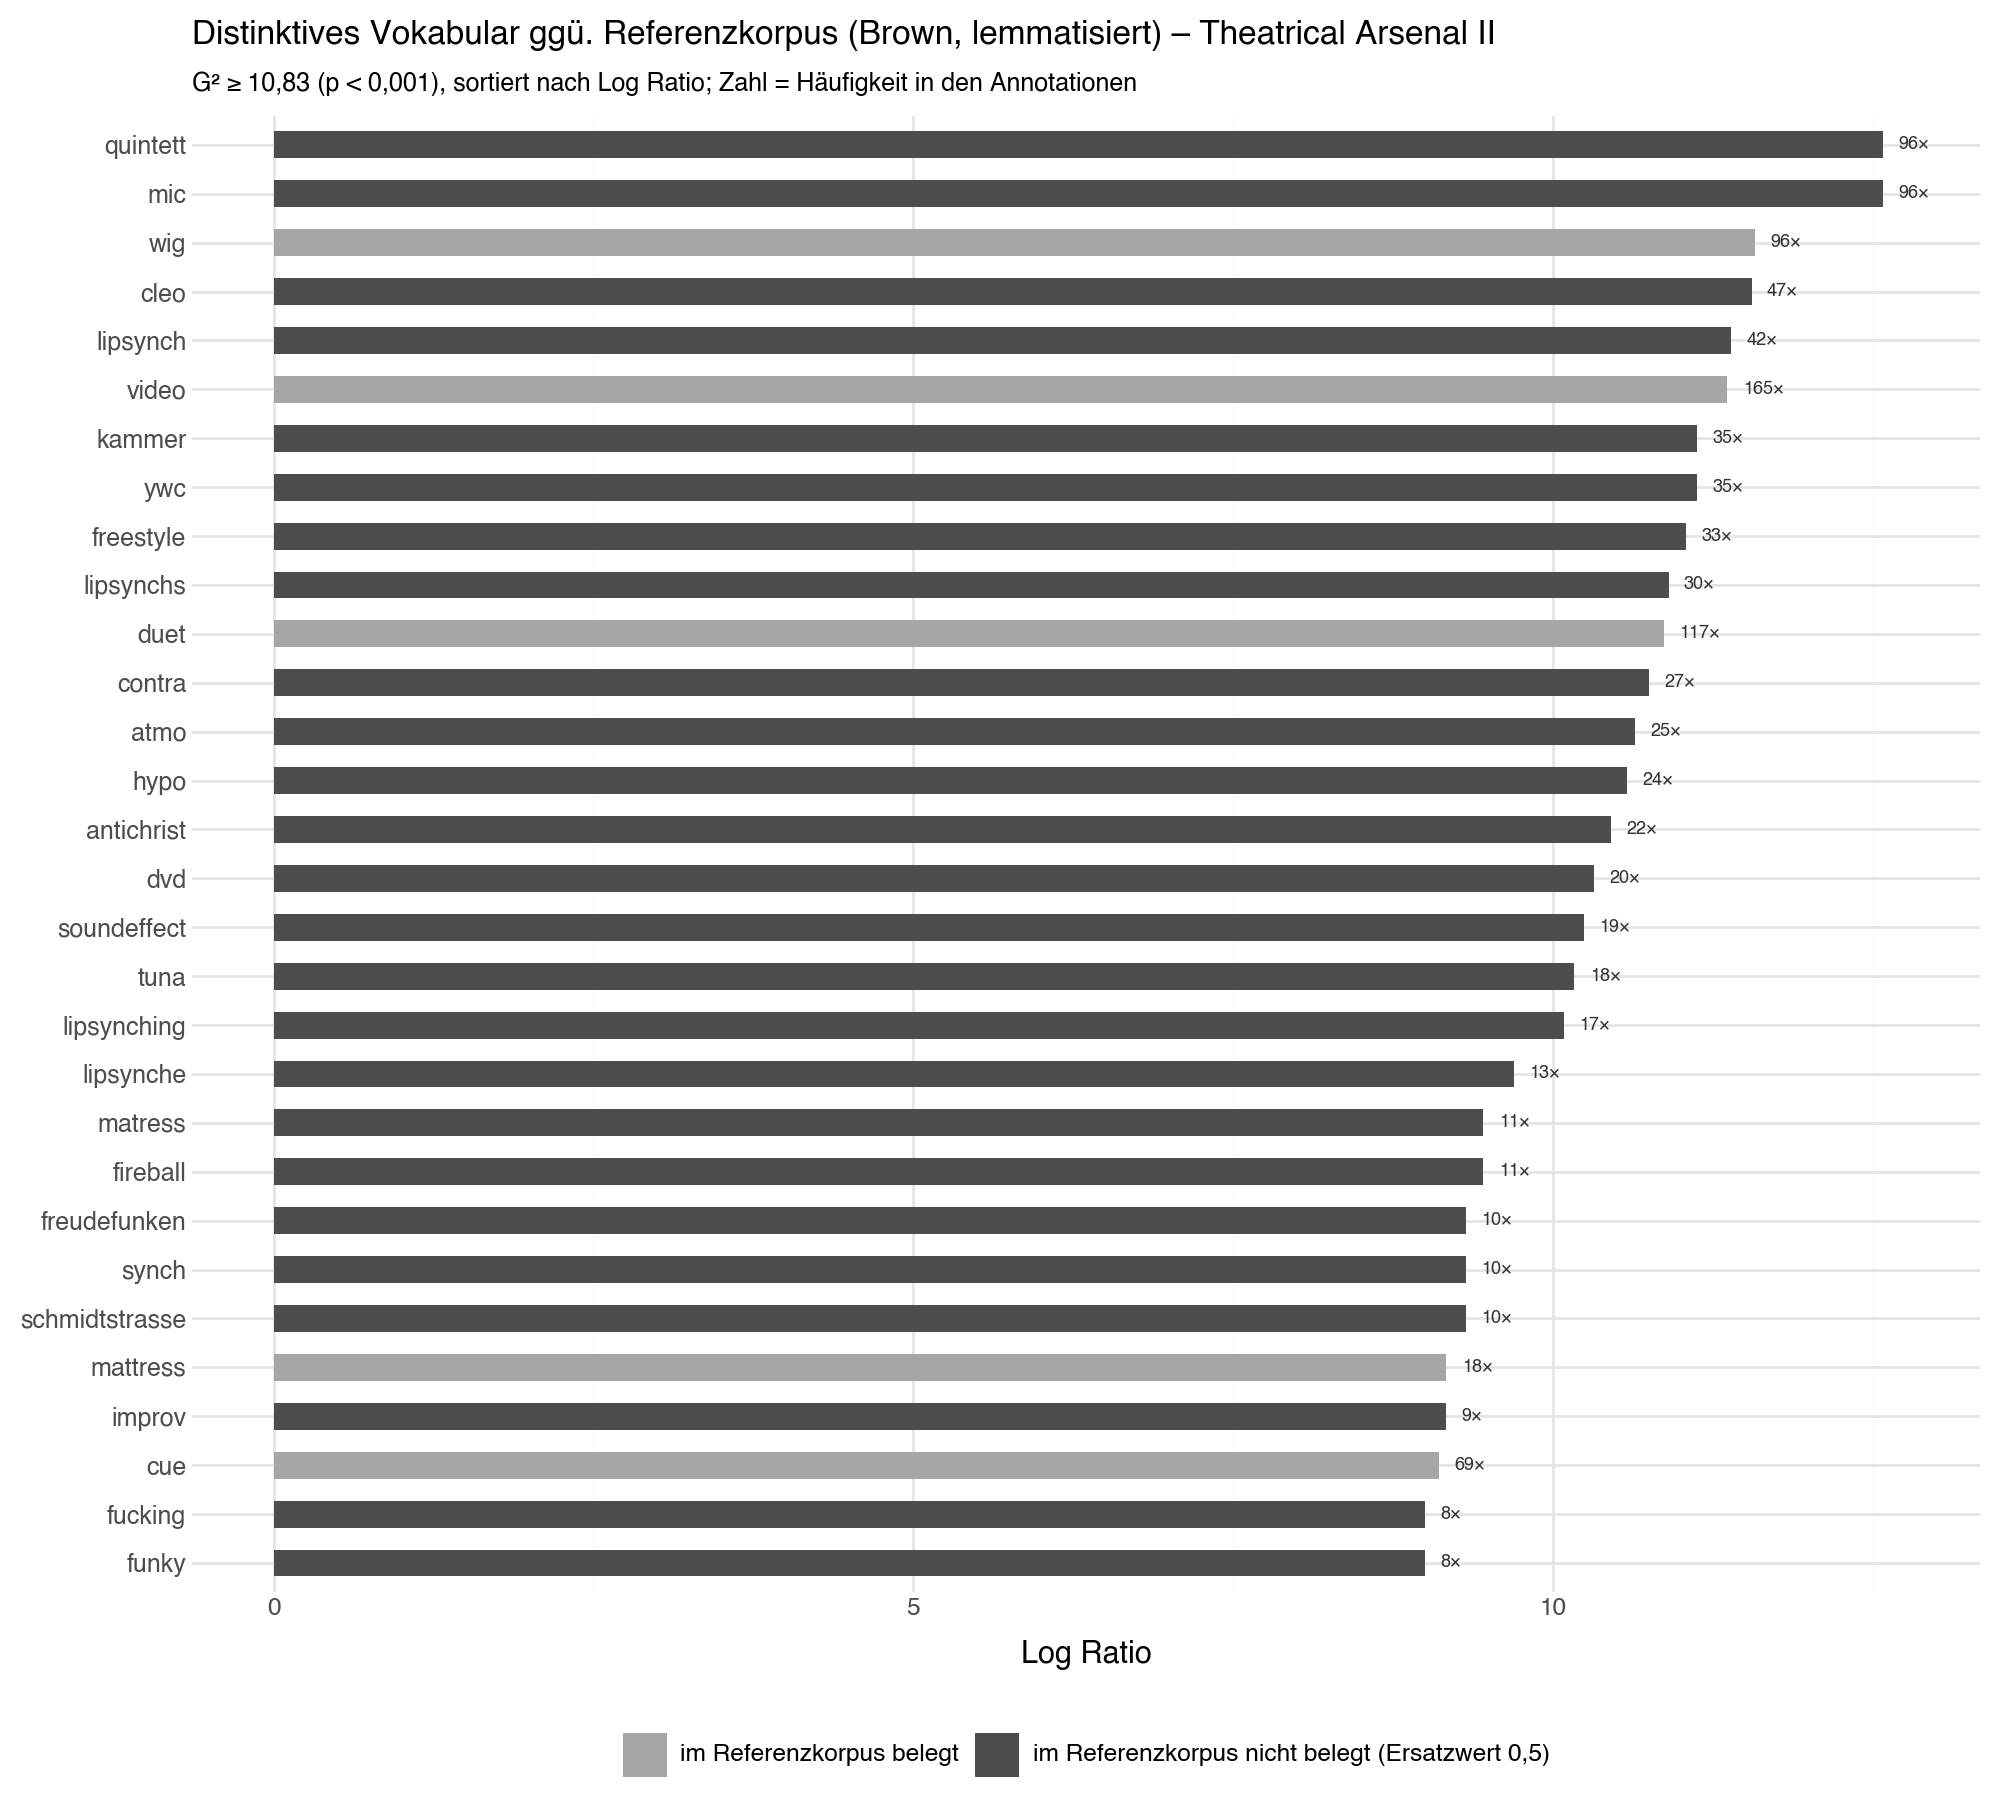

In [25]:
def make_keyness_plot(lang=None, top=30):
    df = keyness_sig.head(top).copy()
    df['label'] = df['your_count'].astype(str) + '×'
    absent  = L('im Referenzkorpus nicht belegt (Ersatzwert 0,5)', 'absent from the reference (0.5 substituted)', lang)
    present = L('im Referenzkorpus belegt', 'attested in the reference', lang)
    df['ref'] = np.where(df['ref_count'] == 0, absent, present)
    df['word'] = pd.Categorical(df['word'], categories=df['word'][::-1], ordered=True)
    crit = de_num(G2_CRIT) if (lang or LANG) == 'de' else f'{G2_CRIT}'
    return (ggplot(df, aes(x='word', y='log_ratio', fill='ref'))
     + geom_col(width=0.55)
     + geom_text(aes(label='label'), ha='left', nudge_y=0.12, size=6.5, color='#333333')
     + scale_fill_manual(values={absent: '#4d4d4d', present: '#a6a6a6'}, name='')
     + coord_flip()
     + labs(title=L(f'Distinktives Vokabular ggü. Referenzkorpus (Brown, lemmatisiert) – {PIECE_TITLE}',
                    f'Distinctive Vocabulary vs. Brown (lemmatised) – {PIECE_TITLE}', lang),
            subtitle=L(f'G² ≥ {crit} (p < 0,001), sortiert nach Log Ratio; Zahl = Häufigkeit in den Annotationen',
                       f'G² ≥ {crit} (p < 0.001), ranked by Log Ratio; labels = frequency in the annotations', lang),
            x='', y='Log Ratio')
     + theme(figure_size=(10, 9),
             axis_text_y=element_text(size=9),
             legend_position='bottom'))

p_key = make_keyness_plot()
p_key

## Topic modelling

BERTopic clusters sentence embeddings instead of counting words, which suits the short, telegraphic annotations better than classic bag-of-words topic models (LDA gave heavily overlapping topics on this material).


### BERTopic

Sentences from the cleaned annotations, embedded with `all-MiniLM-L6-v2`, reduced with UMAP (fixed seed) and clustered with HDBSCAN (BERTopic default, `min_cluster_size=10`). A space is inserted after punctuation directly followed by a letter, otherwise BERTopic merges words like `soundeffects.Pari` into one keyword. Unlike in the Sider notebook, the performer names are kept in the topic keywords here, to try them as bridge terms for scene-related topics. To see whether the soundeffects topic depends on the seed, the clustering is repeated with ten other seeds.

In [26]:
from sentence_transformers import SentenceTransformer
from umap import UMAP

print("\n=== BERTopic Analysis (seeded) ===")
BERTOPIC_SEED = 42

sentences = []
timestamps = []
def space_after_punct(text):
    return re.sub(r"([.,;:!?/])(?=[A-Za-z])", r"\1 ", text)

for _, row in text_df.iterrows():
    for sentence in sent_tokenize(space_after_punct(row["clean_text"])):
        sentence_clean = sentence.strip()
        if sentence_clean:
            sentences.append(sentence_clean)
            timestamps.append(row["date"])
print(f"Total sentences: {len(sentences)}")

# the model is downloaded automatically on the first run
embedding_model = SentenceTransformer("all-MiniLM-L6-v2")
embeddings = embedding_model.encode(sentences, show_progress_bar=True)

umap_model = UMAP(n_neighbors=15, n_components=5, min_dist=0.0,
                  metric='cosine', random_state=BERTOPIC_SEED)
# names stay in the keywords ('ander' as bridge term)
vectorizer_model = CountVectorizer(stop_words="english")
topic_model = BERTopic(umap_model=umap_model, vectorizer_model=vectorizer_model)
topics, probs = topic_model.fit_transform(sentences, embeddings)

print(f"Number of topics found: {len(set(topics)) - 1}")
print(f"Outlier sentences (topic -1): {sum(1 for t in topics if t == -1)}")


=== BERTopic Analysis (seeded) ===
Total sentences: 3364


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/106 [00:00<?, ?it/s]

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


Number of topics found: 66
Outlier sentences (topic -1): 632


In [27]:
topic_model.get_topic_info()[['Topic', 'Count', 'Name']].head(20)

,Topic,Count,Name
0,-1,632,-1_music_kammer_manci_yasu
1,0,268,0_freya_freyas_start_says
2,1,227,1_dana_introduction_introduces_performer
3,2,184,2_body_things_arms_legs
4,3,146,3_liz_jone_version_cyril
5,4,139,4_david_morrow_nirvana_freudefunken
6,5,109,5_pari_solo_lipsynching_lock
7,6,101,6_video_lights_light_music
8,7,95,7_roberta_cyril_tilman_leave
9,8,84,8_esther_manci_ywc_duet


In [28]:
# Inspect a specific topic by ID (edit the number)
topic_model.get_topic(5)

[('pari', 0.13483199761129688),
 ('solo', 0.05276958700902842),
 ('lipsynching', 0.04336875980095753),
 ('lock', 0.03757922705036441),
 ('pop', 0.03754609371108269),
 ('lipsynchs', 0.0341122246149896),
 ('slowly', 0.027089105146403156),
 ('pot', 0.025361689277461658),
 ('stool', 0.024346602721147574),
 ('moves', 0.02392910308582579)]

In [29]:
# the soundeffects topic discussed in the dissertation
def topic_words(tid):
    return [w for w, _ in topic_model.get_topic(tid)]

candidates = []
for tid in topic_model.get_topic_info()['Topic']:
    if tid == -1:
        continue
    ws = topic_words(tid)[:10]
    score = sum(w.startswith('soundeffect') or w in ('ander', 'foley', 'effects') for w in ws)
    if score >= 2:
        candidates.append((score, -tid, tid))
candidates.sort(reverse=True)
assert candidates, 'No soundeffects topic found, inspect get_topic_info() manually.'
TARGET_TID = candidates[0][2]
target_label = '_'.join([str(TARGET_TID)] + topic_words(TARGET_TID)[:4])
print(f'Selected topic: {TARGET_TID}  ->  {target_label}')

Selected topic: 14  ->  14_ander_soundeffects_sings_effects


In [30]:
# Top-10 keywords + c-TF-IDF scores of the target topic
kw = pd.DataFrame(topic_model.get_topic(TARGET_TID)[:10], columns=['word', 'score'])
kw

,word,score
0,ander,0.148651
1,soundeffects,0.127559
2,sings,0.076535
3,effects,0.072838
4,playback,0.058452
5,mic,0.042058
6,cables,0.038968
7,foley,0.036529
8,joins,0.036520
9,cut,0.033109


In [31]:
# same embeddings, UMAP seeds 0-9: Jaccard overlap of the target topic's sentences with the best match
target_idx = {i for i, t in enumerate(topics) if t == TARGET_TID}
stab_rows = []
for seed in range(10):
    tm_s = BERTopic(umap_model=UMAP(n_neighbors=15, n_components=5, min_dist=0.0,
                                    metric='cosine', random_state=seed),
                    vectorizer_model=vectorizer_model)
    topics_s, _ = tm_s.fit_transform(sentences, embeddings)
    members = {}
    for i, t in enumerate(topics_s):
        if t != -1:
            members.setdefault(t, set()).add(i)
    best_tid, best_j = None, 0.0
    for t, idx in members.items():
        j = len(target_idx & idx) / len(target_idx | idx)
        if j > best_j:
            best_tid, best_j = t, j
    words_s = [w for w, _ in tm_s.get_topic(best_tid)][:4] if best_tid is not None else []
    stab_rows.append({'seed': seed, 'topics': len(members),
                      'best_match': '_'.join([str(best_tid)] + words_s), 'jaccard': round(best_j, 2)})
stability = pd.DataFrame(stab_rows)
print(stability.to_string(index=False))
print(f"Median Jaccard overlap with the target topic of the seed-{BERTOPIC_SEED} run: {stability['jaccard'].median():.2f}")

 seed  topics                                best_match  jaccard
    0      73 33_soundeffects_ander_effects_soundeffect     0.51
    1      75    13_ander_soundeffects_effects_playback     0.96
    2      74       11_ander_soundeffects_sings_effects     1.00
    3      74       11_ander_soundeffects_sings_effects     1.00
    4      72       12_ander_soundeffects_sings_effects     1.00
    5      70       14_ander_soundeffects_effects_sings     0.96
    6      78       13_ander_soundeffects_sings_effects     1.00
    7      71       14_ander_soundeffects_sings_effects     1.00
    8      73       15_ander_soundeffects_sings_effects     1.00
    9      70       12_ander_soundeffects_sings_effects     1.00
Median Jaccard overlap with the target topic of the seed-42 run: 1.00


In [32]:
# topic per recording day, zero on days without it
day_stamps = [pd.Timestamp(t).normalize() for t in timestamps]
topics_over_time = topic_model.topics_over_time(docs=sentences, topics=topics, timestamps=day_stamps)
single_topic = topics_over_time[topics_over_time['Topic'] == TARGET_TID].copy().sort_values('Timestamp')

recording_days = pd.DatetimeIndex(sorted(set(day_stamps)), name='date')
per_day = (single_topic.set_index('Timestamp')[['Frequency', 'Words']]
           .reindex(recording_days).reset_index())
per_day['Frequency'] = per_day['Frequency'].fillna(0).astype(int)

per_day[per_day['Frequency'] > 0].assign(date=lambda d: d['date'].dt.date).reset_index(drop=True)

,date,Frequency,Words
0,2009-10-22,1,"emphasized, dynamic, contrary, ander, does"
1,2009-10-26,4,"breaking, ander, reinserting, keys, away"
2,2009-10-27,2,"shouting, till, tripod, man, ander"
3,2009-10-29,1,"effects, duet, ander, sound, soundeffects"
4,2009-10-30,3,"effects, sounds, ander, solo, stands"
5,2009-11-02,2,"plus, ander, soundeffects, sings, effects"
6,2009-11-09,3,"foley, ander, maintaining, carries, distances"
7,2009-11-10,2,"effects, minimal, ander, diagonal, exit"
8,2009-11-12,5,"soundeffects, ander, altered, artificially, pr..."
9,2009-11-13,5,"soundeffects, drinking, ander, cut, anders"


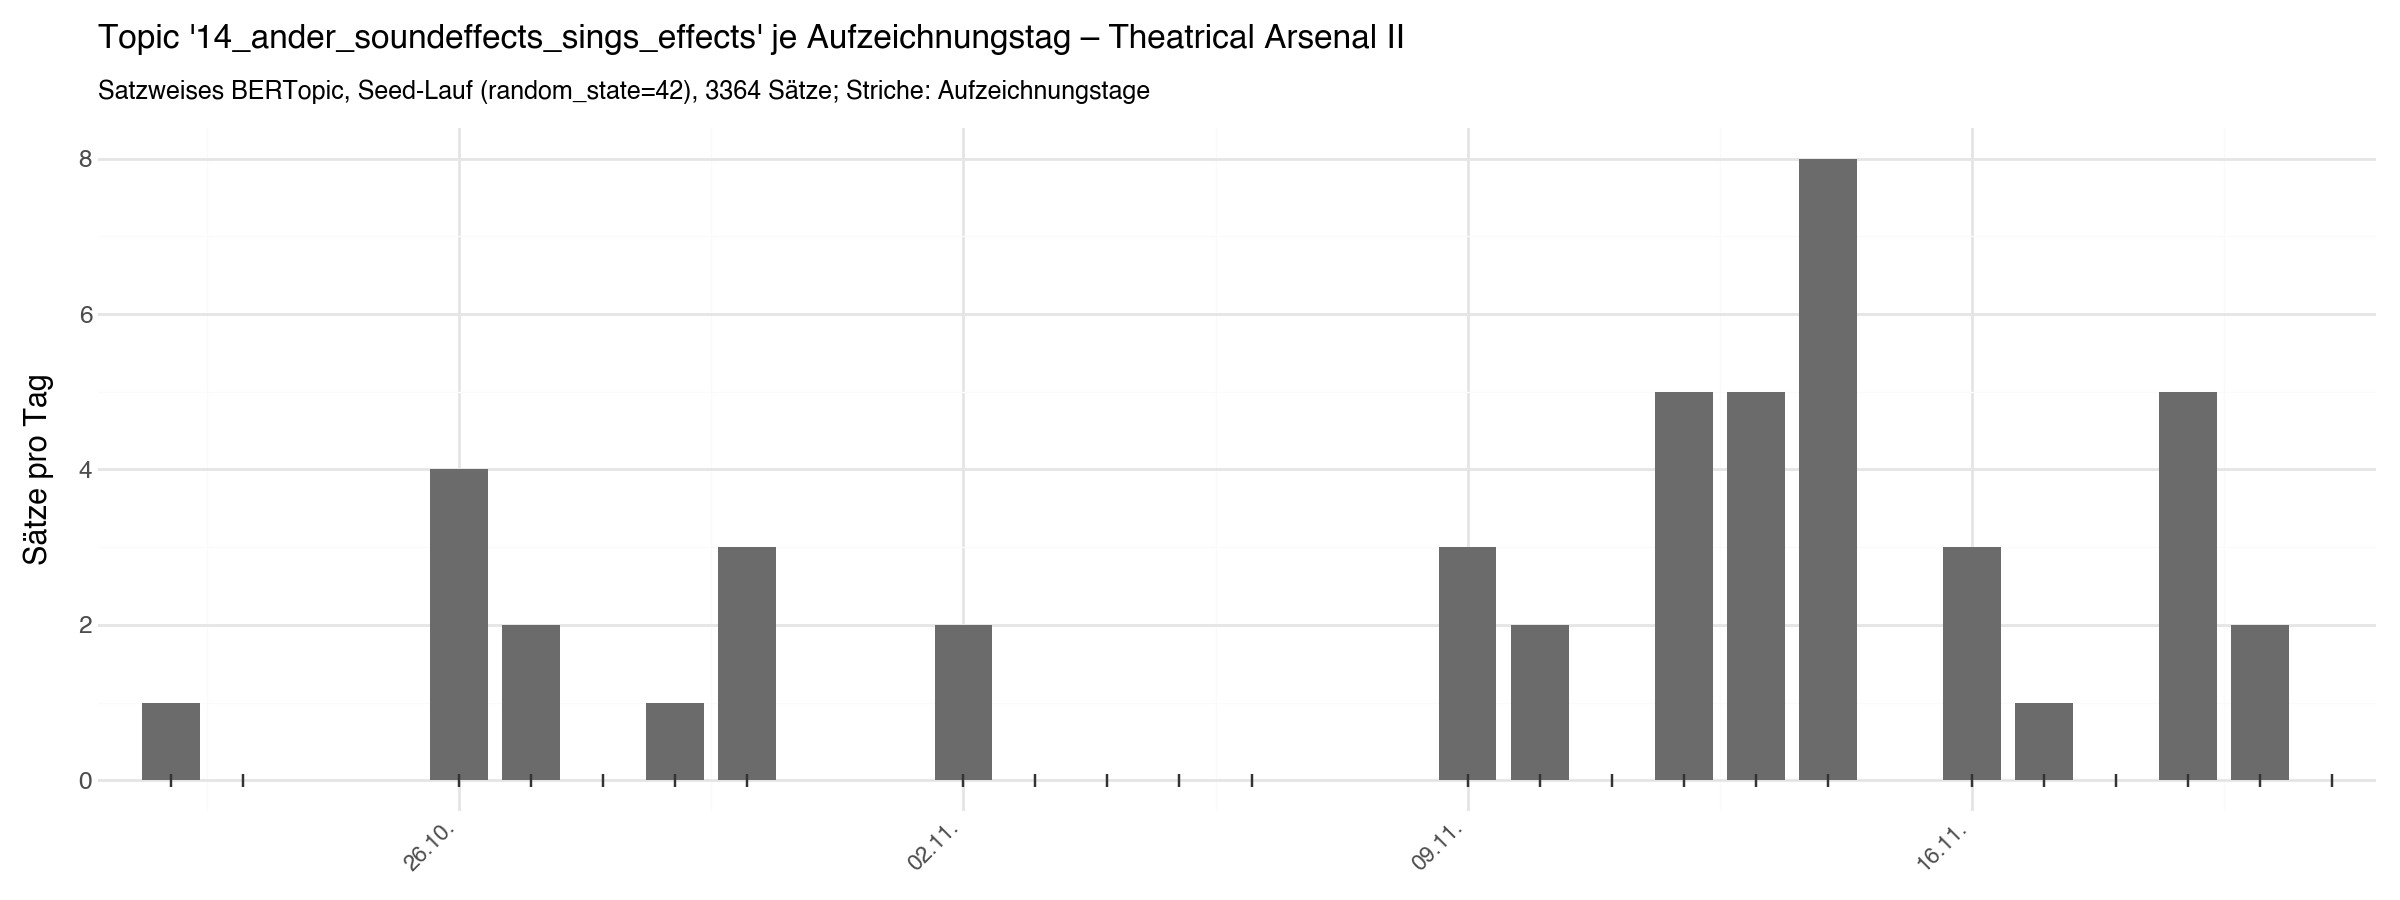

In [33]:
def make_topic_time_plot(lang=None):
    present = per_day[per_day['Frequency'] > 0]
    return (
        ggplot(per_day, aes(x='date', y='Frequency'))
        + geom_col(data=present, fill=BAR_GREY, width=0.8)
        + geom_point(aes(y=0), shape='|', size=2.2, color='#333333')
        + scale_x_datetime(date_breaks='1 week', date_labels='%d.%m.', expand=(0.02, 0))
        + labs(title=L(f"Topic '{target_label}' je Aufzeichnungstag – {PIECE_TITLE}",
                       f"Topic '{target_label}' per recording day – {PIECE_TITLE}", lang),
               subtitle=L(f'Satzweises BERTopic, Seed-Lauf (random_state={BERTOPIC_SEED}), {len(sentences)} Sätze; '
                          'Striche: Aufzeichnungstage',
                          f'Sentence-level BERTopic, seeded run (random_state={BERTOPIC_SEED}), {len(sentences)} sentences; '
                          'ticks: recording days', lang),
               x='', y=L('Sätze pro Tag', 'Sentences per day', lang))
        + theme(figure_size=(12, 4.5),
                axis_text_x=element_text(rotation=45, hjust=1, size=8))
    )

p_topic = make_topic_time_plot()
p_topic

### Topic clusters

2D projection of the sentence embeddings, three thematic topics highlighted.

Highlighted topics: {14: '14_ander_soundeffects_sings_effects', 5: '5_pari_solo_lipsynching_lock', 6: '6_video_lights_light_music'}


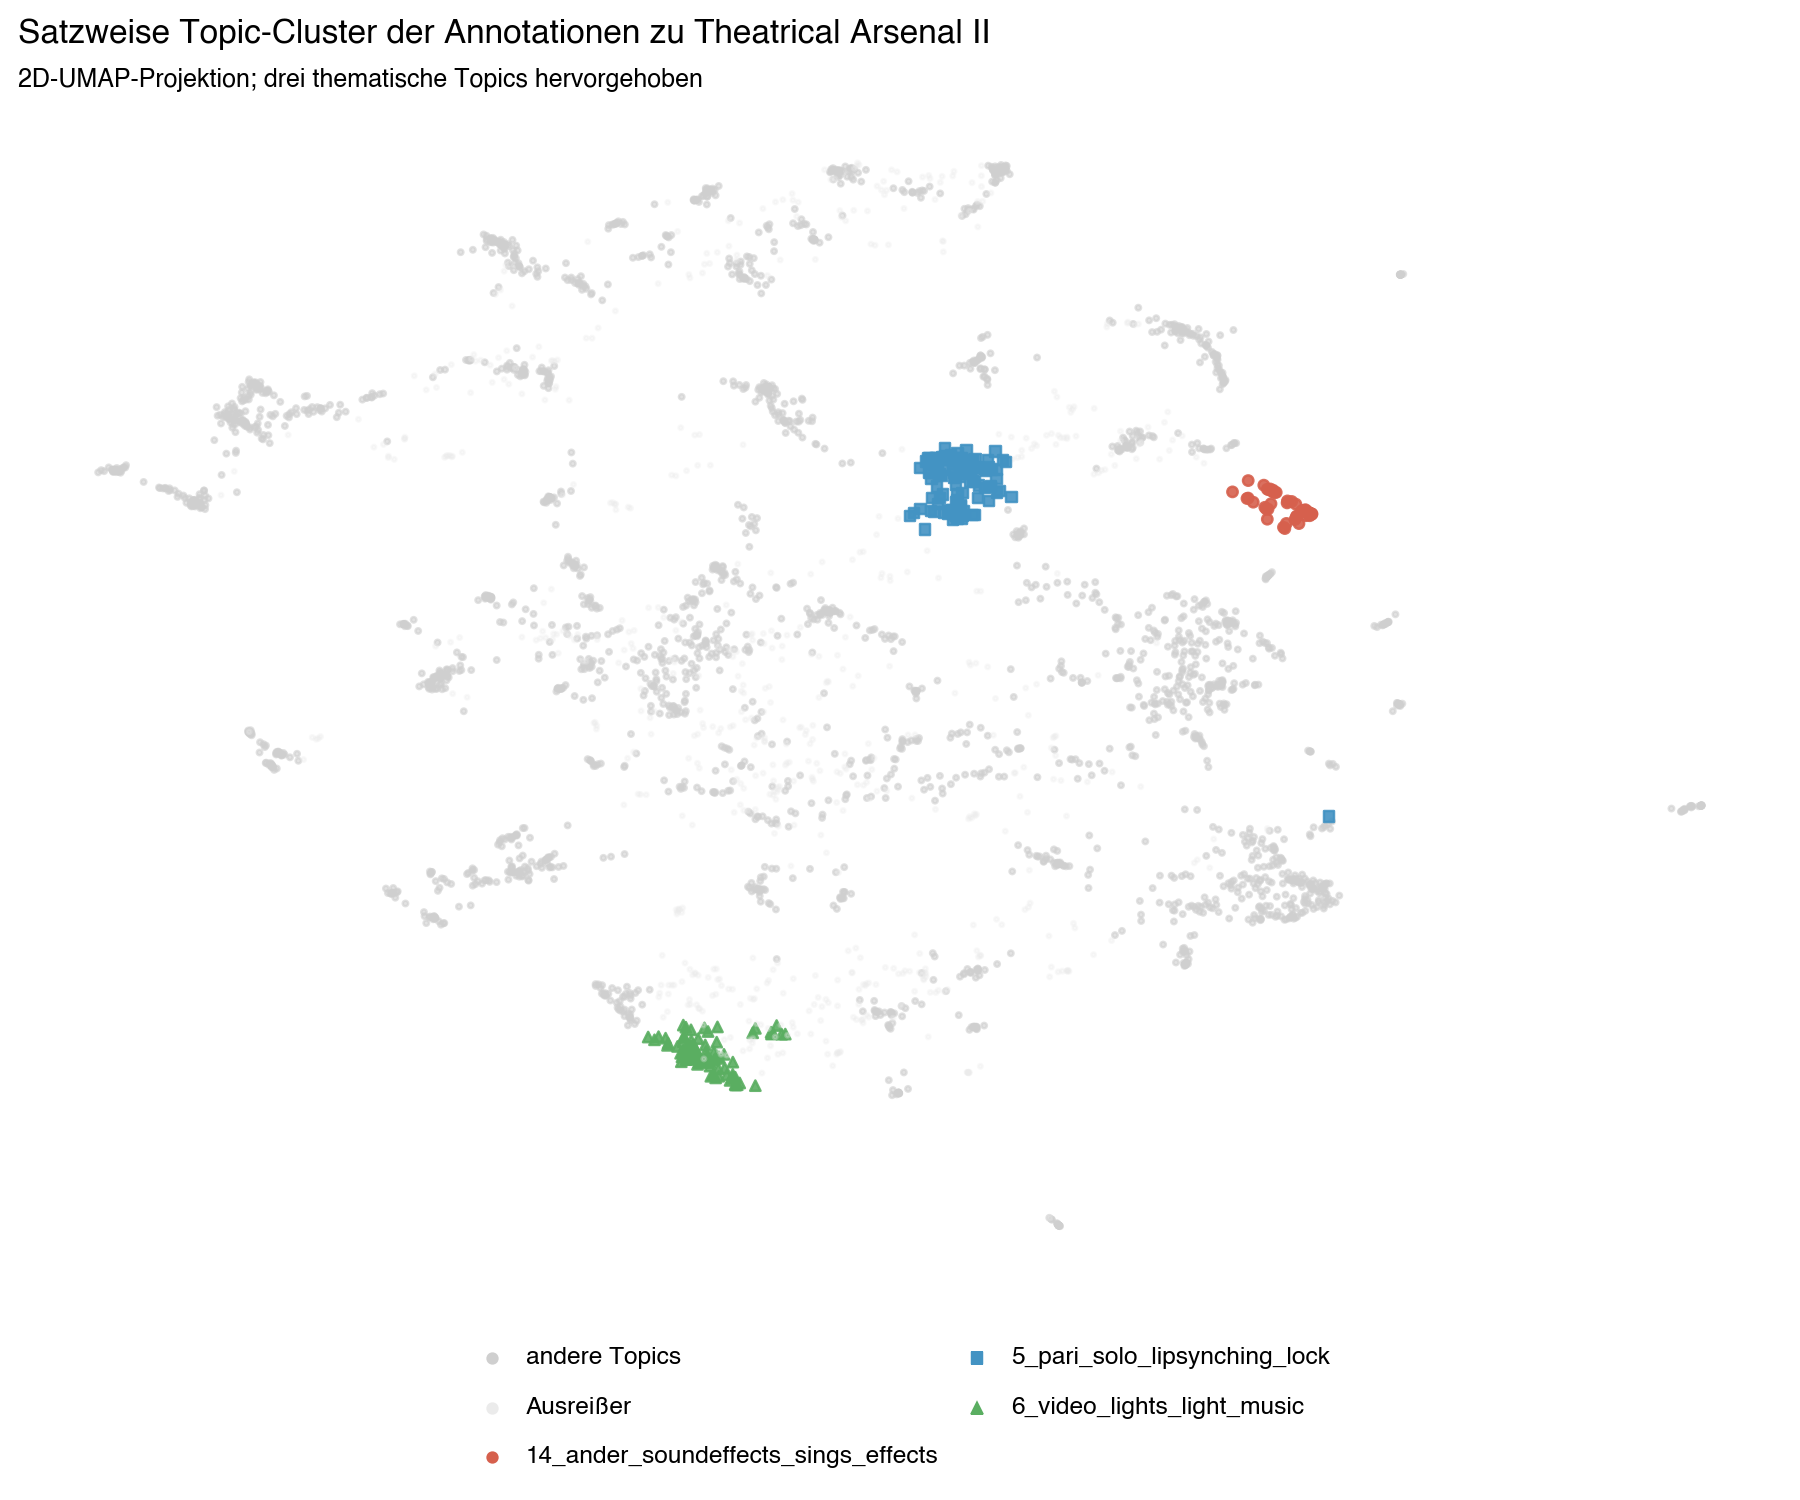

In [34]:
# separate 2D UMAP of the same embeddings
HIGHLIGHT_SPECS = [
    ('soundeffects', ('soundeffects', 'soundeffect', 'foley')),
    ('lipsynch',     ('lipsynching', 'lipsynch', 'lipsynchs', 'lipsync')),
    ('light/video',  ('video', 'lights', 'light', 'silence')),
]
highlight = {}
topic_ids = [t for t in topic_model.get_topic_info()['Topic'] if t != -1]
for spec_name, spec_words in HIGHLIGHT_SPECS:
    ranked = sorted(((sum(w in spec_words for w in topic_words(t)[:10]), -t, t) for t in topic_ids
                     if t not in highlight), reverse=True)
    assert ranked[0][0] >= 1, f'No topic found for {spec_name}, inspect get_topic_info().'
    tid = ranked[0][2]
    highlight[tid] = '_'.join([str(tid)] + topic_words(tid)[:4])
print('Highlighted topics:', highlight)

emb2d = UMAP(n_neighbors=15, n_components=2, min_dist=0.0,
             metric='cosine', random_state=BERTOPIC_SEED).fit_transform(embeddings)
proj = pd.DataFrame({'x': emb2d[:, 0], 'y': emb2d[:, 1], 'topic': topics})

def make_projection_plot(lang=None):
    lab_outlier = L('Ausreißer', 'outlier', lang)
    lab_other   = L('andere Topics', 'other topics', lang)
    df = proj.copy()
    df['group'] = df['topic'].map(highlight)
    df.loc[df['group'].isna() & (df['topic'] == -1), 'group'] = lab_outlier
    df['group'] = df['group'].fillna(lab_other)
    order = [lab_other, lab_outlier] + list(highlight.values())
    df['group'] = pd.Categorical(df['group'], categories=order, ordered=True)
    df = df.sort_values('group')  # draw highlighted topics last (on top)
    colors = {lab_other: '#cfcfcf', lab_outlier: '#ebebeb',
              **dict(zip(highlight.values(), ['#d6604d', '#4393c3', '#5aae61']))}
    shapes = {lab_other: 'o', lab_outlier: 'o',
              **dict(zip(highlight.values(), ['o', 's', '^']))}
    sizes  = {lab_other: 0.6, lab_outlier: 0.4, **{v: 1.6 for v in highlight.values()}}
    alphas = {lab_other: 0.6, lab_outlier: 0.3, **{v: 0.9 for v in highlight.values()}}
    return (
        ggplot(df, aes(x='x', y='y', color='group', shape='group', size='group', alpha='group'))
        + geom_point()
        + scale_color_manual(values=colors, name='')
        + scale_shape_manual(values=shapes, name='')
        + scale_size_manual(values=sizes, guide=None)
        + scale_alpha_manual(values=alphas, guide=None)
        + guides(color=guide_legend(ncol=2), shape=guide_legend(ncol=2))
        + labs(title=L(f'Satzweise Topic-Cluster der Annotationen zu {PIECE_TITLE}',
                       f'Sentence-level topic clusters of the annotations to {PIECE_TITLE}', lang),
               subtitle=L('2D-UMAP-Projektion; drei thematische Topics hervorgehoben',
                          '2D UMAP projection; three thematic topics highlighted', lang),
               x='', y='')
        + theme(figure_size=(9, 7.5),
                axis_text=element_blank(), axis_ticks=element_blank(),
                panel_grid=element_blank(),
                legend_position='bottom')
    )

p_clust = make_projection_plot()
p_clust

## Figures for the dissertation

German labels, print size, written to `figures/`.

In [35]:
FIG_DIR.mkdir(exist_ok=True)

def save_print(p, name, size=PRINT_SIZE, extra=None):
    p = p + PRINT_THEME + theme(figure_size=size)
    if extra is not None:
        p = p + extra
    p.save(FIG_DIR / name, dpi=300, verbose=False)
    print('saved', FIG_DIR / name)

save_print(p_bigram, 'ta2_bigram_new_version_per_day_de.png')                    # Abb. 4.7
save_print(make_track_plot('de'), 'ta2_repertoire_terms_per_day_de.png')         # Abb. 4.10
save_print(make_keyness_plot('de'), 'ta2_keyness_brown_de.png', size=(5.8, 6.2)) # Abb. 4.9
save_print(make_projection_plot('de'), 'ta2_topic_clusters_de.png', size=(5.8, 5.0),
           extra=theme(axis_text=element_blank(), axis_ticks=element_blank()))   # Abb. 4.11
save_print(make_topic_time_plot('de'), 'ta2_topic_soundeffects_per_day_de.png')  # Abb. 4.12

kw.to_csv(FIG_DIR / 'ta2_topic_soundeffects_keywords.csv', index=False)                       # Tab. 4.5
(per_day[per_day['Frequency'] > 0].assign(date=lambda d: d['date'].dt.date)
 .to_csv(FIG_DIR / 'ta2_topic_soundeffects_per_day.csv', index=False))                        # Tab. 4.6
keyness_sig.head(30).to_csv(FIG_DIR / 'ta2_keyness_brown_top30.csv', index=False)
corr_report.to_csv(FIG_DIR / 'ta2_correlation_report.csv', index=False)
stability.to_csv(FIG_DIR / 'ta2_topic_seed_stability.csv', index=False)

saved figures/ta2_bigram_new_version_per_day_de.png
saved figures/ta2_repertoire_terms_per_day_de.png


saved figures/ta2_keyness_brown_de.png
saved figures/ta2_topic_clusters_de.png


saved figures/ta2_topic_soundeffects_per_day_de.png
